# Checkpoint 5 — Random Forest × XGBoost × LightGBM
**Data Science e Statistical Computing · FIAP 2026 · Prof. Jones Egydio**

**Projeto aplicado:** previsão de *churn* (cancelamento) de clientes de telecomunicações — aprendizado supervisionado, classificação binária, comparação rigorosa de três algoritmos de árvores sob um único protocolo experimental.

| Integrante | RM |
|---|---|
| Camila Mendonça | RM565491 |
| Julia Silva | RM564670 |
| Luana Luo | RM562271 |
| Sidyellen Garcia | RM566408 |

**Roteiro:** 1) Problema e base · 2) Wrangling e EDA · 3) Variáveis e desenho experimental · 4) Baselines · 5) Tuning (Grid Search × Optuna) · 6) Seleção do modelo e over/underfitting · 7) Teste final, consistência, deploy.

**Regras do protocolo (guardrails):**
1. `D_teste` só é tocado **uma vez**, no Exercício 7.
2. Toda transformação que aprende parâmetros (imputer, scaler, OneHotEncoder) vive dentro de `Pipeline`/`ColumnTransformer` → **zero data leakage**.
3. Os 3 algoritmos usam **exatamente os mesmos folds** (`StratifiedKFold(5, shuffle=True, random_state=42)`) e a **mesma métrica principal** (ROC-AUC).
4. Grid Search **e** Optuna rodam para **todos** os 3 modelos → 6 processos de tuning, 9 configurações na tabela de decisão.

In [ ]:
import sys, time, json, warnings
from pathlib import Path

# raiz do projeto (funciona rodando de notebooks/ ou da raiz)
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import optuna
from scipy.stats import chi2_contingency
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import (GridSearchCV, cross_val_score, cross_val_predict,
                                     learning_curve)
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             confusion_matrix, log_loss)

from src.data_loader import (RANDOM_STATE, TARGET, ID_COL, DATA_URL, NUMERIC_FEATURES,
                             CATEGORICAL_FEATURES, FEATURES, load_raw, split_xy,
                             make_train_test, make_cv)
from src.preprocessing import TelcoCleaner, build_preprocessor, build_pipeline
from src.evaluate import (set_plot_style, evaluate_cv, classification_metrics,
                          get_feature_names, select_champion, SCORING)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

set_plot_style()                      # whitegrid + fonte serifada + sem spines sup./dir. + viridis
pd.set_option("display.max_columns", 50, "display.width", 200)
np.random.seed(RANDOM_STATE)

MODEL_COLORS = dict(zip(["M_RF", "M_XGB", "M_LGBM"], sns.color_palette("viridis", 3)))
ARTIFACTS = ROOT / "artifacts"; ARTIFACTS.mkdir(exist_ok=True)
print("Raiz do projeto:", ROOT)

Raiz do projeto: C:\Users\camil\OneDrive - Grupo Alun\FIAP\Segundo Ano\Statistical Computing\cp5 data science


---
# Exercício 1 — Definição do Problema e da Base de Dados

## 1.1 Contexto de negócio
Operadoras de telecomunicações vivem de receita recorrente. **Reter** um cliente existente custa tipicamente bem menos do que **adquirir** um novo, então identificar *antes* quem vai cancelar permite agir (desconto, upgrade de plano, contato proativo) enquanto ainda há tempo. O cancelamento (*churn*) é, porém, um evento relativamente raro e influenciado por muitos fatores (contrato, tempo de casa, serviços contratados, forma de pagamento) — um cenário ideal para aprendizado supervisionado.

## 1.2 Problema preditivo e pertinência do aprendizado supervisionado
* Temos um **histórico rotulado**: cada cliente tem atributos cadastrais/contratuais e o desfecho conhecido (cancelou ou não).
* Queremos aprender $f: X \rightarrow y$ para estimar, para **novos clientes**, a probabilidade de cancelamento.
* Aprendizado supervisionado é pertinente porque o rótulo existe, é binário e as relações são não lineares e com interações (ex.: contrato mensal **×** internet fibra **×** pouco tempo de casa) — exatamente o que ensembles de árvores capturam bem.

## 1.3 Variável-alvo e impacto prático
* **y = `Churn`** (1 = cliente cancelou, 0 = permaneceu) → **classificação binária**.
* **ŷ** (classe) e, principalmente, $\hat p = P(y=1\mid x)$ (probabilidade) alimentam uma **lista priorizada de clientes em risco** para o time de retenção. Falso negativo = cliente perdido sem ação; falso positivo = incentivo gasto com quem ficaria de qualquer forma. O trade-off é ajustável via limiar sobre $\hat p$.

In [ ]:
df_raw = load_raw()           # baixa automaticamente para data/raw_dataset.csv se não existir
print("Dimensões originais (linhas, colunas):", df_raw.shape)
df_raw.head()

Dimensões originais (linhas, colunas): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.4 Base de dados — fonte, unidade observacional, dimensões e licença
* **Dataset:** *Telco Customer Churn* — amostra pública da IBM (IBM Cognos Analytics / Watson Analytics *sample data*), de uma operadora fictícia da Califórnia. Distribuído também no Kaggle ("blastchar/telco-customer-churn").
* **Fonte usada pelo projeto (download automático em `src/data_loader.py`):** `https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv`
* **Licença/uso:** dados de amostra publicados pela IBM para fins educacionais e demonstrações, sem informação pessoal real; usados aqui estritamente para fins acadêmicos (consulte o repositório de origem para os termos vigentes).
* **Unidade observacional:** **um cliente** (uma linha por `customerID`).
* **Dimensões originais:** 7.043 linhas × 21 colunas (20 atributos + alvo).

### Dicionário de dados
| Coluna | Tipo | Descrição |
|---|---|---|
| `customerID` | identificador | Código único do cliente (**removido**: não generaliza e permitiria memorização) |
| `gender` | categórica | Gênero (Female/Male) |
| `SeniorCitizen` | binária (0/1) | Cliente idoso (≥ 65 anos) |
| `Partner` | categórica | Possui cônjuge/parceiro |
| `Dependents` | categórica | Possui dependentes |
| `tenure` | numérica (meses) | Meses de permanência como cliente |
| `PhoneService` | categórica | Possui telefonia |
| `MultipleLines` | categórica | Múltiplas linhas (Yes/No/No phone service) |
| `InternetService` | categórica | Tipo de internet (DSL / Fiber optic / No) |
| `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | categóricas | Serviços adicionais (Yes/No/No internet service) |
| `Contract` | categórica | Tipo de contrato (Month-to-month / One year / Two year) |
| `PaperlessBilling` | categórica | Fatura digital |
| `PaymentMethod` | categórica | Forma de pagamento (4 categorias) |
| `MonthlyCharges` | numérica (US$) | Valor cobrado por mês |
| `TotalCharges` | numérica (US$) | Total cobrado até hoje (vem como texto no CSV) |
| **`Churn`** | **alvo** | Cliente cancelou no último mês (Yes/No) |

## 1.5 Métrica principal
**ROC-AUC** (área sob a curva ROC), por quatro razões:
1. **Classes desbalanceadas** (~26% de churn): acurácia é enganosa (um modelo "ninguém cancela" já teria ~74%).
2. **Independe do limiar**: mede a qualidade do *ranking* de risco, que é o uso real (priorizar clientes); o limiar de corte é decisão de negócio posterior.
3. Tem interpretação probabilística direta: $P(\hat p_{\text{positivo}} > \hat p_{\text{negativo}})$.
4. É estável e adequada para comparar modelos sob o mesmo CV.

**Métricas secundárias:** Acurácia, Precision, Recall, F1 e PR-AUC (área sob a curva Precision-Recall, mais sensível à classe minoritária).

,n,%
Churn,,
No,5174,73.46
Yes,1869,26.54


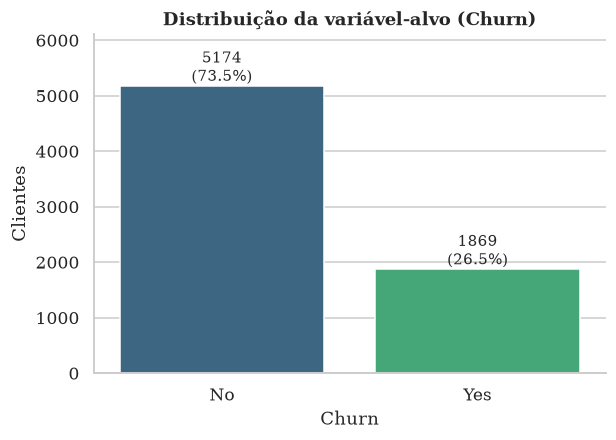

In [ ]:
# Distribuição da variável-alvo
counts = df_raw[TARGET].value_counts()
pct = df_raw[TARGET].value_counts(normalize=True) * 100
display(pd.DataFrame({"n": counts, "%": pct.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_raw, x=TARGET, order=["No", "Yes"], palette="viridis", ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}\n({p.get_height()/len(df_raw):.1%})",
                (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=10)
ax.set_title("Distribuição da variável-alvo (Churn)"); ax.set_xlabel("Churn"); ax.set_ylabel("Clientes")
ax.set_ylim(0, counts.max() * 1.18)
plt.show()

**Leitura:** ~26,5% dos clientes cancelaram → desbalanceamento moderado (≈ 2,8 : 1). Por isso (i) a métrica principal é ROC-AUC, (ii) todas as divisões usam **estratificação**, e (iii) acurácia isolada não será usada para decidir.

---
# Exercício 2 — Data Wrangling e Análise Exploratória

## 2.1 Diagnóstico: tipos, nulos, duplicados e anomalias

In [ ]:
print("== Tipos ==")
display(df_raw.dtypes.to_frame("dtype").T)

print("\n== Nulos por coluna (NaN) ==")
nulls = df_raw.isna().sum(); display(nulls[nulls > 0] if nulls.sum() else pd.Series({"total de NaN": 0}))

print("== Duplicados ==")
print("Linhas duplicadas (todas as colunas):", df_raw.duplicated().sum())
print("customerID duplicado:", df_raw[ID_COL].duplicated().sum())
print("Linhas duplicadas ignorando customerID:", df_raw.drop(columns=ID_COL).duplicated().sum())

print("\n== Anomalia de tipo: TotalCharges é 'object' (texto) ==")
tc_num = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
bad = df_raw[tc_num.isna()]
print(f"Valores não numéricos em TotalCharges: {len(bad)}  (valores distintos: {bad['TotalCharges'].unique()})")
display(bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]].head())
print("tenure desses registros:", sorted(bad["tenure"].unique()), "→ clientes recém-chegados, ainda não faturados.")

print("\n== Categorias de cada variável categórica ==")
display(pd.DataFrame({c: [sorted(df_raw[c].unique().tolist())] for c in CATEGORICAL_FEATURES if c != "SeniorCitizen"}).T.rename(columns={0: "valores"}))
print("\n== Estatísticas das numéricas ==")
display(df_raw[["tenure", "MonthlyCharges"]].describe().T)

== Tipos ==


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str



== Nulos por coluna (NaN) ==


total de NaN    0
dtype: int64

== Duplicados ==
Linhas duplicadas (todas as colunas): 0
customerID duplicado: 0
Linhas duplicadas ignorando customerID: 22

== Anomalia de tipo: TotalCharges é 'object' (texto) ==
Valores não numéricos em TotalCharges: 11  (valores distintos: <ArrowStringArray>
[' ']
Length: 1, dtype: str)


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No


tenure desses registros: [np.int64(0)] → clientes recém-chegados, ainda não faturados.

== Categorias de cada variável categórica ==


,valores
gender,"[Female, Male]"
Partner,"[No, Yes]"
Dependents,"[No, Yes]"
PhoneService,"[No, Yes]"
MultipleLines,"[No, No phone service, Yes]"
InternetService,"[DSL, Fiber optic, No]"
OnlineSecurity,"[No, No internet service, Yes]"
OnlineBackup,"[No, No internet service, Yes]"
DeviceProtection,"[No, No internet service, Yes]"
TechSupport,"[No, No internet service, Yes]"



== Estatísticas das numéricas ==


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


**Diagnóstico:**
* **Anomalia 1 — `TotalCharges` como texto:** 11 registros contêm *string vazia* (não é `NaN`, por isso `isna()` não os acusa). Todos têm `tenure = 0`: são clientes que acabaram de entrar e ainda não receberam fatura → **TotalCharges = 0** é o valor semanticamente correto (regra de negócio, *sem estatística aprendida* ⇒ sem leakage).
* **Anomalia 2 — `SeniorCitizen` é 0/1 numérico**, mas é **categoria binária** (a magnitude não significa nada) → convertida para `No/Yes`.
* **Categorias com "No internet service"/"No phone service":** são redundantes com `InternetService`/`PhoneService`, mas carregam informação estrutural e são mantidas (o One-Hot lida bem; árvores as exploram).
* **Duplicados:** `customerID` é único (0 duplicados), porém **22 linhas são idênticas em todos os atributos** quando o identificador é descartado. São perfis idênticos de clientes distintos; mantê-las faria cópias exatas caírem em treino **e** validação/teste, inflando o score. Serão removidas **após** descartar o ID.
* **Nulos reais (NaN):** nenhum.

## 2.2 Wrangling (cada decisão justificada) e classes de pré-processamento
As correções de **tipo** são implementadas na classe `TelcoCleaner` (`src/preprocessing.py`), um transformador **sem estado** (não aprende nada ⇒ não vaza informação). Ela é a **1ª etapa do pipeline final**, de modo que a aplicação Streamlit recebe os dados exatamente do mesmo jeito. As etapas que *aprendem* parâmetros (imputação, padronização, One-Hot) ficam no `ColumnTransformer` (`build_preprocessor`) e só veem o treino de cada fold.

| Decisão | Justificativa |
|---|---|
| `TotalCharges` → numérico; vazio com `tenure==0` → 0,0 | Corrige tipo; valor lógico, não estatístico |
| `SeniorCitizen` 0/1 → `No`/`Yes` | É categoria; evita tratá-la como escala |
| Remover `customerID` | Identificador: zero poder de generalização e risco de memorização |
| Remover 22 duplicatas (pós-remoção do ID) | Evita cópias entre treino e validação/teste |
| `Churn` Yes/No → 1/0 | Alvo numérico para as métricas |
| Imputer (mediana / moda) no pipeline | Salvaguarda para dados novos (app) — aprendido **só no treino** |
| StandardScaler + OneHotEncoder(`handle_unknown="ignore"`) no pipeline | Nenhum parâmetro vaza do teste; categorias novas não quebram a predição |

In [ ]:
df = TelcoCleaner().fit_transform(df_raw)            # correção de tipos (stateless)
df = df.drop(columns=ID_COL)                         # identificador
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)     # duplicatas de perfil
print(f"Duplicatas removidas: {n_before - len(df)}")
df[TARGET] = df[TARGET].map({"Yes": 1, "No": 0}).astype(int)
df.dtypes.to_frame("dtype").T

Duplicatas removidas: 22


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,float64,int64


## 2.3 Visualizações analíticas

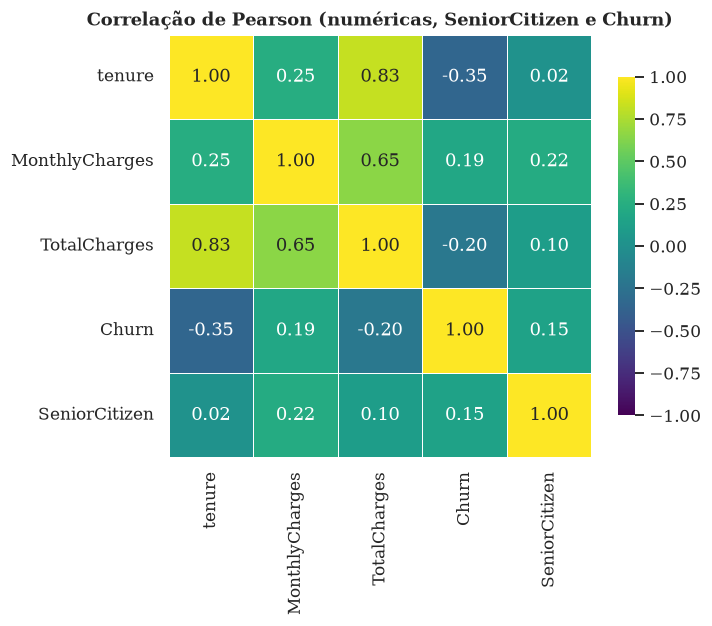

tenure           -0.352
TotalCharges     -0.197
SeniorCitizen     0.152
MonthlyCharges    0.195


In [ ]:
# Viz 1 — Correlação (numéricas + alvo + SeniorCitizen)
num_df = df[NUMERIC_FEATURES + [TARGET]].copy()
num_df["SeniorCitizen"] = (df["SeniorCitizen"] == "Yes").astype(int)
corr = num_df.corr()

fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlação de Pearson (numéricas, SeniorCitizen e Churn)")
plt.show()
print(corr[TARGET].drop(TARGET).sort_values().round(3).to_string())

**Interpretação (Viz 1):** `tenure` tem a correlação **negativa** mais forte com o churn (quanto mais tempo de casa, menor a chance de cancelar); `MonthlyCharges` correlaciona **positivamente** (planos mais caros cancelam mais). `TotalCharges` é muito correlacionada com `tenure` (≈ `tenure × MonthlyCharges`) — **multicolinearidade** que não prejudica árvores, mas explica por que sua associação direta com o alvo é mais fraca do que a de `tenure`.

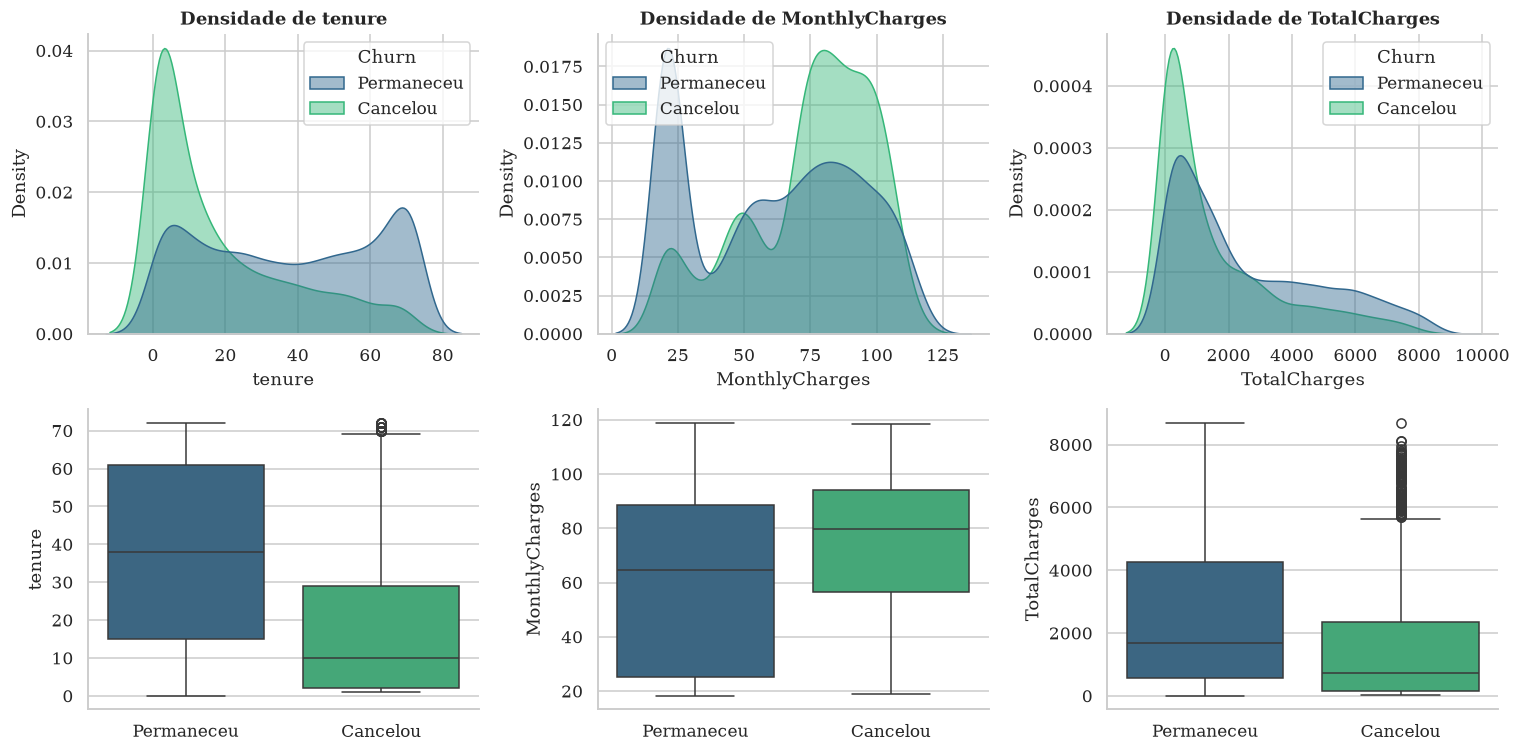

tenure       MonthlyCharges       TotalCharges        
      median  mean         median  mean       median    mean
Churn                                                       
0       38.0  37.6           64.5  61.3       1683.0  2554.8
1       10.0  18.1           79.7  74.6        713.1  1541.4

In [ ]:
# Viz 2 — Distribuição das numéricas por classe do alvo
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
labels = {0: "Permaneceu", 1: "Cancelou"}
for j, col in enumerate(NUMERIC_FEATURES):
    sns.kdeplot(data=df, x=col, hue=df[TARGET].map(labels), fill=True, common_norm=False,
                palette="viridis", alpha=.45, ax=axes[0, j])
    axes[0, j].set_title(f"Densidade de {col}")
    sns.boxplot(data=df, x=df[TARGET].map(labels), y=col, palette="viridis", ax=axes[1, j])
    axes[1, j].set_xlabel("")
plt.tight_layout(); plt.show()
display(df.groupby(TARGET)[NUMERIC_FEATURES].agg(["median", "mean"]).round(1))

**Interpretação (Viz 2):** quem cancela é, tipicamente, **cliente novo** (mediana de `tenure` muito menor — a distribuição se concentra nos primeiros meses) e paga **mensalidade mais alta**. A distribuição de `tenure` dos que ficam é bimodal (recém-chegados e clientes antigos fidelizados), o que sugere relações não lineares — um ponto a favor de modelos baseados em árvores. Há sobreposição considerável, logo nenhuma variável isolada separa as classes.

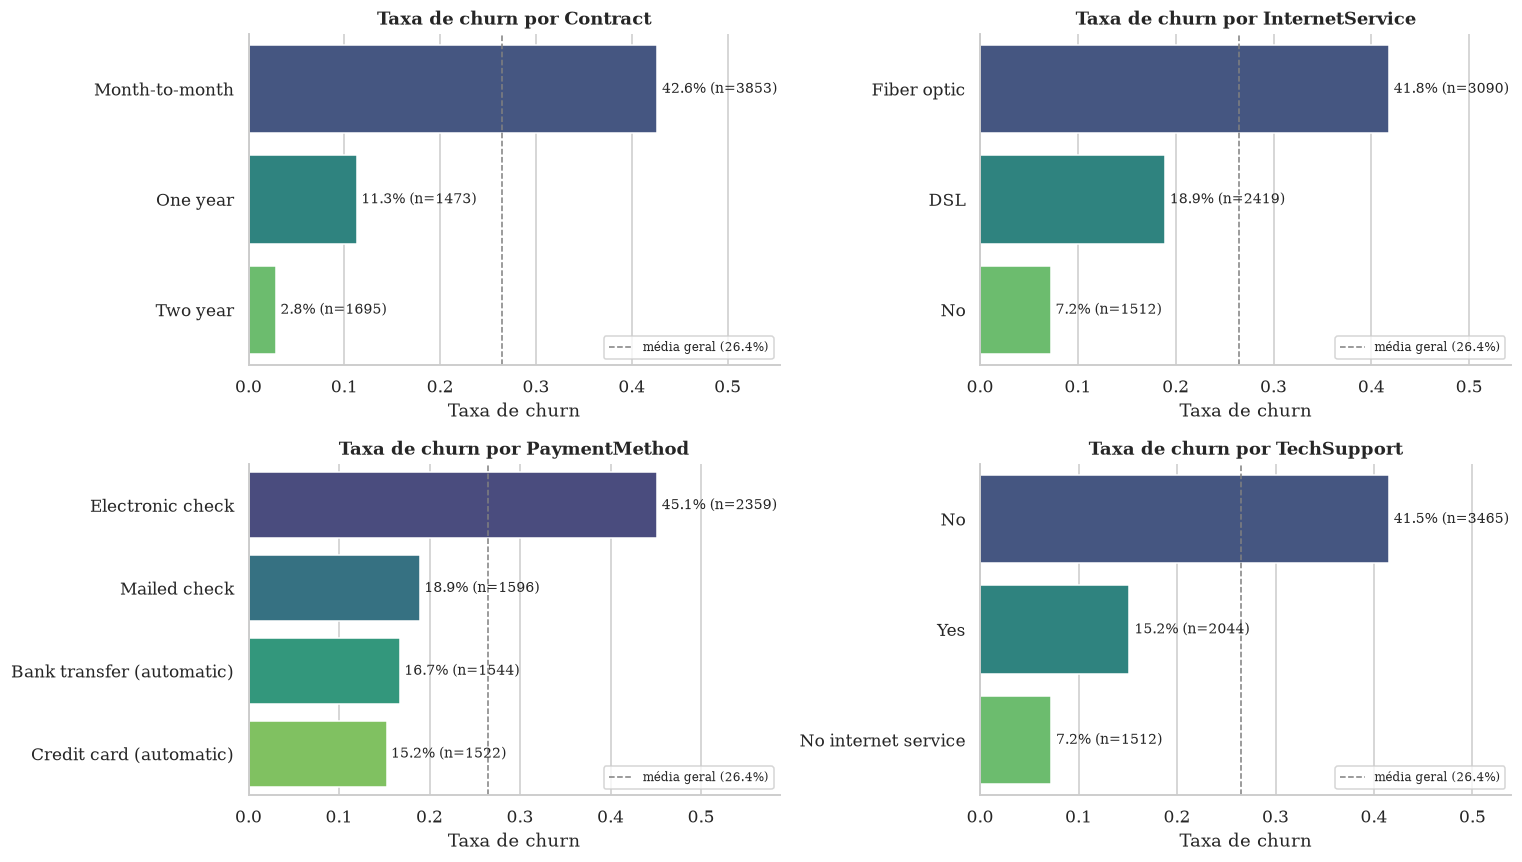

In [ ]:
# Viz 3 — Taxa de churn nas categorias mais críticas
crit = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
overall = df[TARGET].mean()
for ax, col in zip(axes.ravel(), crit):
    rate = df.groupby(col)[TARGET].agg(["mean", "size"]).sort_values("mean", ascending=False)
    sns.barplot(x=rate["mean"], y=rate.index, palette="viridis", ax=ax)
    ax.axvline(overall, color="gray", ls="--", lw=1, label=f"média geral ({overall:.1%})")
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(m + .005, i, f"{m:.1%} (n={n})", va="center", fontsize=9)
    ax.set_title(f"Taxa de churn por {col}"); ax.set_xlabel("Taxa de churn"); ax.set_ylabel("")
    ax.set_xlim(0, rate["mean"].max() * 1.3); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Interpretação (Viz 3):** o **tipo de contrato** é o fator mais discriminante: contrato *mensal* tem taxa de churn muitas vezes maior que o de 1 ou 2 anos (fidelização contratual protege). **Fibra óptica** apresenta churn bem acima de DSL e de quem não tem internet; **pagamento por cheque eletrônico** concentra o maior churn entre as formas de pagamento; e **sem suporte técnico** o churn é bem mais alto. Esses são os "pontos de dor" que o modelo deve capturar e que depois devem aparecer na importância de variáveis.

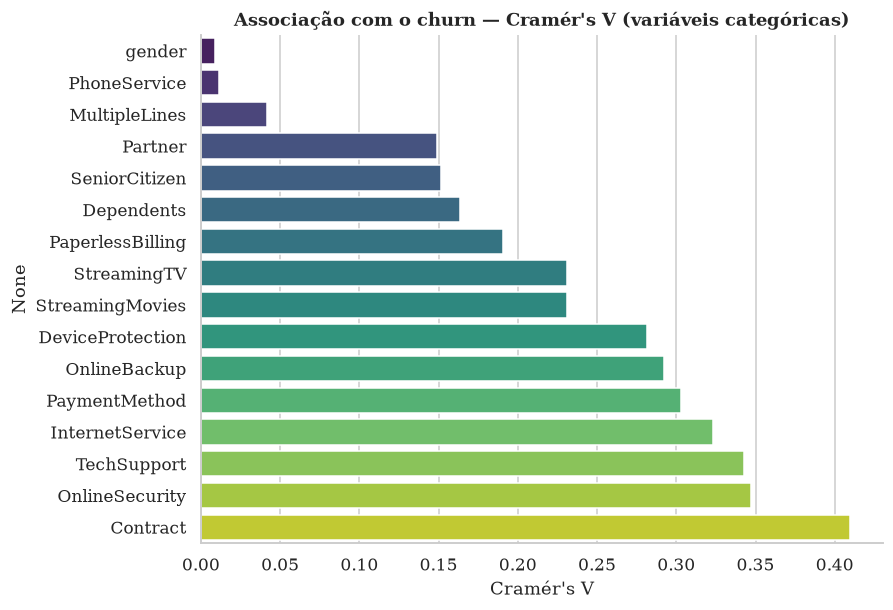

Contract           0.410
OnlineSecurity     0.347
TechSupport        0.343
InternetService    0.323
PaymentMethod      0.303
dtype: float64

In [ ]:
# Viz 4 — Força de associação categórica × alvo (Cramér's V)
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt((chi2 / n) / (min(r, k) - 1))

cv_assoc = pd.Series({c: cramers_v(df[c], df[TARGET]) for c in CATEGORICAL_FEATURES}).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=cv_assoc.values, y=cv_assoc.index, palette="viridis", ax=ax)
ax.set_title("Associação com o churn — Cramér's V (variáveis categóricas)"); ax.set_xlabel("Cramér's V")
plt.show()
cv_assoc.sort_values(ascending=False).head(5).round(3)

**Interpretação (Viz 4):** `Contract`, `OnlineSecurity`, `TechSupport`, `InternetService` e `PaymentMethod` lideram a associação; `gender`, `PhoneService` e `MultipleLines` são praticamente irrelevantes (V ≈ 0). Isso antecipa o que as importâncias do modelo devem confirmar — e mostra que variáveis de baixo sinal serão naturalmente ignoradas pelas árvores (não precisamos filtrá-las manualmente, o que evitaria uma seleção de variáveis feita fora do CV).

## 2.4 Estado final do wrangling

In [ ]:
print("df.shape final:", df.shape)
assert df.duplicated().sum() == 0, "ainda há duplicatas"
assert df.isna().sum().sum() == 0, "ainda há nulos"
print("Duplicatas residuais :", int(df.duplicated().sum()))
print("Nulos residuais      :", int(df.isna().sum().sum()))
print("customerID presente? :", ID_COL in df.columns)
print("Proporção de churn   :", f"{df[TARGET].mean():.2%}")

df.shape final: (7021, 20)
Duplicatas residuais : 0
Nulos residuais      : 0
customerID presente? : False
Proporção de churn   : 26.45%


---
# Exercício 3 — Escolha de Variáveis e Desenho Experimental

## 3.1 Matriz X e vetor y
* **y** = `Churn` (1/0).
* **X** = 19 atributos: 3 numéricos (`tenure`, `MonthlyCharges`, `TotalCharges`) + 16 categóricos.
* **Removidos:** `customerID` (identificador). **Features pós-evento / vazamento direto:** a base não contém colunas medidas *depois* do cancelamento (como motivo de churn ou *churn score*, que existem em outras versões do dataset da IBM e **não** estão aqui); `TotalCharges` é um acumulado até a data de observação e é uma característica legítima do cliente no momento da predição (equivale a `tenure × mensalidade`, derivado de atributos já conhecidos antes do desfecho).
* **Seleção de variáveis:** nenhuma etapa supervisionada fora do CV foi usada — as árvores fazem seleção implícita e a análise do Exercício 2 serviu apenas para entendimento.

In [ ]:
X, y = split_xy(df)
print("X:", X.shape, "| y:", y.shape)
print("Numéricas   :", NUMERIC_FEATURES)
print("Categóricas :", len(CATEGORICAL_FEATURES), "colunas")

X: (7021, 19) | y: (7021,)
Numéricas   : ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas : 16 colunas


## 3.2 Divisão treino/teste (80/20, `random_state=42`, estratificada) e validação cruzada
`D_teste` é separado **agora** e **fica guardado**: a partir daqui, apenas `X_train, y_train` serão usados até o Exercício 7. O objeto de CV (`StratifiedKFold`, 5 folds, `shuffle=True`, `random_state=42`) é criado **uma única vez** e reutilizado por baseline, Grid Search, Optuna, curva de aprendizado e predições out-of-fold — garantindo **os mesmos folds** para os 3 algoritmos.

In [ ]:
X_train, X_test, y_train, y_test = make_train_test(X, y, test_size=0.2)   # D_treino / D_teste
cv = make_cv(5)                                                           # mesmo CV para tudo

print(f"D_treino: {X_train.shape}  | churn = {y_train.mean():.2%}")
print(f"D_teste : {X_test.shape}  | churn = {y_test.mean():.2%}   <- guardado, NÃO será tocado até o Ex. 7")
print("Folds de CV:", cv.get_n_splits(), "| shuffle:", cv.shuffle, "| random_state:", cv.random_state)
print("Índices disjuntos treino/teste:", set(X_train.index).isdisjoint(X_test.index))

D_treino: (5616, 19)  | churn = 26.44%
D_teste : (1405, 19)  | churn = 26.48%   <- guardado, NÃO será tocado até o Ex. 7
Folds de CV: 5 | shuffle: True | random_state: 42
Índices disjuntos treino/teste: True


## 3.3 Métricas
| Papel | Métrica |
|---|---|
| **Principal (decide tudo)** | **ROC-AUC** (média nos folds de CV) |
| Secundárias | Acurácia, Precision, Recall, F1 (limiar 0,5) e PR-AUC |
| Diagnóstico | Gap = $S_{treino} - S_{CV}$ e desvio-padrão entre folds |

O score de **treino** é a média do ROC-AUC calculado nos mesmos dados em que cada fold foi treinado (`return_train_score=True`), de forma que o gap compara maçãs com maçãs.

---
# Exercício 4 — Baselines dos Três Modelos de Referência
Cada baseline é um `Pipeline(cleaner → preprocessor → modelo)` com hiperparâmetros **padrão** (apenas `random_state=42`). Medimos: score de treino, média e desvio do CV, tempo de treino (`time.perf_counter`, 1 fit em todo `D_treino`) e métricas secundárias.

In [ ]:
def make_model(name, **params):
    if name == "M_RF":
        return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params)
    if name == "M_XGB":
        return XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss", **params)
    if name == "M_LGBM":
        return LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, **params)
    raise ValueError(name)

MODEL_NAMES = ["M_RF", "M_XGB", "M_LGBM"]
configs = {}        # (modelo, estratégia) -> pipeline NÃO treinado (para clonar/refazer)
rows = []           # linhas da tabela de decisão

for name in MODEL_NAMES:
    pipe = build_pipeline(make_model(name))
    configs[(name, "Baseline")] = pipe
    rows.append(evaluate_cv(name, "Baseline", pipe, X_train, y_train, cv))

baseline_df = pd.DataFrame(rows)
cols = ["Modelo", "Score Treino", "Score Validação (CV)", "Std CV", "Gap (Δ)", "Tempo treino (s)",
        "CV accuracy", "CV precision", "CV recall", "CV f1", "CV pr_auc"]
display(baseline_df[cols].round(4))

,Modelo,Score Treino,Score Validação (CV),Std CV,Gap (Δ),Tempo treino (s),CV accuracy,CV precision,CV recall,CV f1,CV pr_auc
0,M_RF,1.0000,0.8235,0.0149,0.1765,0.3692,0.7885,0.6323,0.4795,0.5452,0.6100
1,M_XGB,0.9898,0.8216,0.0182,0.1682,0.3715,0.7883,0.6152,0.5320,0.5701,0.6228
2,M_LGBM,0.9628,0.8332,0.0160,0.1296,0.2514,0.7929,0.6317,0.5199,0.5703,0.6478


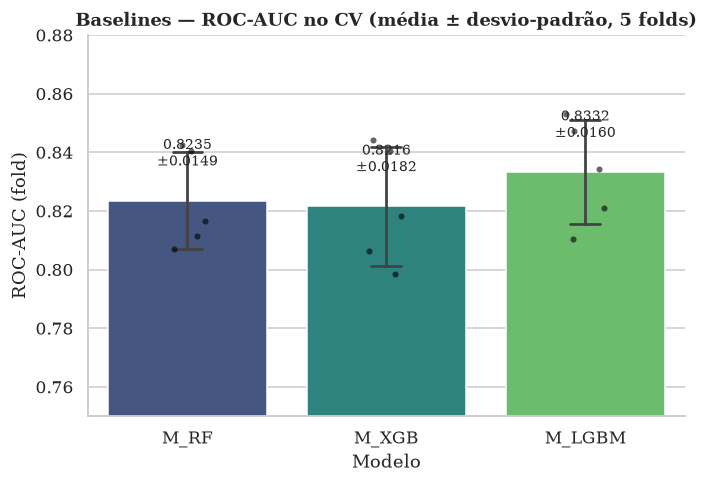

In [ ]:
# Gráfico de barras com barras de erro (± 1 desvio-padrão entre folds)
long = pd.DataFrame({"Modelo": np.repeat(baseline_df["Modelo"], cv.get_n_splits()),
                     "ROC-AUC (fold)": np.concatenate(baseline_df["_folds"].values)})
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=long, x="Modelo", y="ROC-AUC (fold)", errorbar="sd", capsize=.15, palette="viridis",
            err_kws={"linewidth": 1.8}, ax=ax)
sns.stripplot(data=long, x="Modelo", y="ROC-AUC (fold)", color="black", size=4, alpha=.6, ax=ax)
for i, r in baseline_df.iterrows():
    ax.text(i, r["Score Validação (CV)"] + 0.012, f"{r['Score Validação (CV)']:.4f}\n±{r['Std CV']:.4f}",
            ha="center", fontsize=9)
ax.set_ylim(0.75, 0.88); ax.set_title("Baselines — ROC-AUC no CV (média ± desvio-padrão, 5 folds)")
plt.show()

In [ ]:
# Indícios preliminares de over/underfitting (automático a partir dos números)
for _, r in baseline_df.iterrows():
    nivel = ("OVERFITTING severo" if r["Gap (Δ)"] > 0.10 else
             "overfitting moderado" if r["Gap (Δ)"] > 0.04 else "gap pequeno")
    print(f"{r['Modelo']:7s} treino={r['Score Treino']:.4f}  CV={r['Score Validação (CV)']:.4f}  "
          f"gap={r['Gap (Δ)']:.4f} → {nivel}")
print("\nReferência de underfitting: um score de CV próximo de 0,5 (ou treino ≈ CV em valor baixo). Aqui os CV ficam ~0,82-0,84.")

M_RF    treino=1.0000  CV=0.8235  gap=0.1765 → OVERFITTING severo
M_XGB   treino=0.9898  CV=0.8216  gap=0.1682 → OVERFITTING severo
M_LGBM  treino=0.9628  CV=0.8332  gap=0.1296 → OVERFITTING severo

Referência de underfitting: um score de CV próximo de 0,5 (ou treino ≈ CV em valor baixo). Aqui os CV ficam ~0,82-0,84.


**Discussão dos baselines:**
* **Random Forest** (árvores profundas, sem poda): treino praticamente perfeito (AUC ≈ 1,0) contra ≈ 0,82 em validação → **overfitting severo** (alta variância): cada árvore memoriza o treino; o ensemble reduz variância mas não elimina a memorização.
* **XGBoost** (padrão: `max_depth=6`, 100 árvores, `learning_rate=0.3`): taxa de aprendizado alta + árvores relativamente profundas ⇒ treino ≈ 0,99 contra ≈ 0,82 em validação → **overfitting severo** e o pior CV dos três.
* **LightGBM** (padrão: 100 árvores, `learning_rate=0.1`, `num_leaves=31`): melhor CV (≈ 0,833) e **menor gap** entre os três (≈ 0,13), mas **ainda é overfitting** (treino ≈ 0,96).
* **Nenhum baseline sofre de underfitting** (scores de CV claramente acima do acaso e treino alto). O espaço de melhoria está em **regularizar** (profundidade, folhas mínimas, taxa de aprendizado menor/mais árvores) — é o objetivo do tuning.

---
# Exercício 5 — Tuning com Grid Search e Optuna
Ambas as estratégias usam **o mesmo `cv`** e **a mesma métrica (ROC-AUC)**, só em `D_treino`. `D_teste` permanece intocado.

## 5.1 Grid Search
Grids coerentes, variando **complexidade** (`max_depth`, `min_samples_leaf`/`min_child_samples`), **quantidade de árvores** (`n_estimators`) e **aprendizado** (`learning_rate`).

| Modelo | Hiperparâmetros (valores) | Nº combinações |
|---|---|---|
| M_RF | `n_estimators` {100, 300} × `max_depth` {4, 8, 12, None} × `min_samples_leaf` {1, 5, 10, 20} | 32 |
| M_XGB | `n_estimators` {100, 300} × `max_depth` {2, 3, 5} × `learning_rate` {0,03; 0,1} × `subsample` {0,8; 1,0} | 24 |
| M_LGBM | `n_estimators` {100, 300} × `max_depth` {3, 5, 7} × `learning_rate` {0,03; 0,1} × `min_child_samples` {20, 50} | 24 |

In [ ]:
GRIDS = {
    "M_RF": {"model__n_estimators": [100, 300], "model__max_depth": [4, 8, 12, None],
             "model__min_samples_leaf": [1, 5, 10, 20]},
    "M_XGB": {"model__n_estimators": [100, 300], "model__max_depth": [2, 3, 5],
              "model__learning_rate": [0.03, 0.1], "model__subsample": [0.8, 1.0]},
    "M_LGBM": {"model__n_estimators": [100, 300], "model__max_depth": [3, 5, 7],
               "model__learning_rate": [0.03, 0.1], "model__min_child_samples": [20, 50]},
}

grid_res = {}
for name in MODEL_NAMES:
    gs = GridSearchCV(build_pipeline(make_model(name)), GRIDS[name], scoring="roc_auc", cv=cv,
                      n_jobs=1, refit=False, return_train_score=True)
    t0 = time.perf_counter(); gs.fit(X_train, y_train); elapsed = time.perf_counter() - t0
    best = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
    grid_res[name] = dict(best_params=best, best_score=gs.best_score_, time=elapsed,
                          n_fits=len(gs.cv_results_["params"]) * cv.get_n_splits(),
                          cv_results=pd.DataFrame(gs.cv_results_))
    print(f"{name:7s} melhor CV ROC-AUC = {gs.best_score_:.4f} | {elapsed:6.1f}s | "
          f"{grid_res[name]['n_fits']} fits | {best}")

pd.DataFrame({n: {"best CV": r["best_score"], "tempo (s)": r["time"], "fits": r["n_fits"],
                  "melhores hiperparâmetros": r["best_params"]} for n, r in grid_res.items()}).T

M_RF    melhor CV ROC-AUC = 0.8491 |  141.5s | 160 fits | {'max_depth': 8, 'min_samples_leaf': 20, 'n_estimators': 300}


M_XGB   melhor CV ROC-AUC = 0.8511 |   90.4s | 120 fits | {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300, 'subsample': 0.8}


M_LGBM  melhor CV ROC-AUC = 0.8493 |   62.4s | 120 fits | {'learning_rate': 0.03, 'max_depth': 3, 'min_child_samples': 50, 'n_estimators': 300}


,best CV,tempo (s),fits,melhores hiperparâmetros
M_RF,0.849113,141.512641,160,"{'max_depth': 8, 'min_samples_leaf': 20, 'n_es..."
M_XGB,0.851111,90.37577,120,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est..."
M_LGBM,0.849258,62.446729,120,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c..."


## 5.2 Optuna (TPE, `seed=42`, ≥ 20 trials por modelo)
A função objetivo monta o mesmo pipeline, sugere hiperparâmetros e retorna a **média do ROC-AUC nos mesmos 5 folds** (`cv`). Usamos **30 trials** por modelo (≥ 20 exigidos), com `TPESampler(seed=42)`.

**Espaço de busca documentado**

| Modelo | Hiperparâmetro | Distribuição |
|---|---|---|
| M_RF | `n_estimators` | inteiro [100, 500] (passo 50) |
| | `max_depth` | inteiro [3, 20] |
| | `min_samples_leaf` | inteiro [1, 40] (log) |
| | `max_features` | categórico {sqrt, log2, 0,5} |
| M_XGB | `n_estimators` | inteiro [100, 600] (passo 50) |
| | `max_depth` | inteiro [2, 8] |
| | `learning_rate` | real [0,01; 0,3] (log) |
| | `subsample`, `colsample_bytree` | real [0,6; 1,0] |
| | `min_child_weight` | inteiro [1, 10] |
| | `reg_lambda` | real [1e-3; 10] (log) |
| M_LGBM | `n_estimators` | inteiro [100, 600] (passo 50) |
| | `num_leaves` | inteiro [8, 64] |
| | `max_depth` | inteiro [2, 10] |
| | `learning_rate` | real [0,01; 0,3] (log) |
| | `min_child_samples` | inteiro [10, 100] |
| | `subsample` (com `subsample_freq=1`), `colsample_bytree` | real [0,6; 1,0] |
| | `reg_lambda` | real [1e-3; 10] (log) |

In [ ]:
def suggest_params(name, trial):
    if name == "M_RF":
        return dict(n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                    max_depth=trial.suggest_int("max_depth", 3, 20),
                    min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 40, log=True),
                    max_features=trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5]))
    if name == "M_XGB":
        return dict(n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
                    max_depth=trial.suggest_int("max_depth", 2, 8),
                    learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                    subsample=trial.suggest_float("subsample", 0.6, 1.0),
                    colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
                    min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
                    reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True))
    if name == "M_LGBM":
        return dict(n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
                    num_leaves=trial.suggest_int("num_leaves", 8, 64),
                    max_depth=trial.suggest_int("max_depth", 2, 10),
                    learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                    min_child_samples=trial.suggest_int("min_child_samples", 10, 100),
                    subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
                    colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
                    reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True))

def make_objective(name):
    def objective(trial):
        pipe = build_pipeline(make_model(name, **suggest_params(name, trial)))
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)  # mesmos folds
        trial.set_user_attr("cv_std", float(scores.std()))
        return float(scores.mean())
    return objective

def run_optuna(name, n_trials, seed):
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed),
                                study_name=f"{name}_seed{seed}")
    t0 = time.perf_counter(); study.optimize(make_objective(name), n_trials=n_trials)
    return study, time.perf_counter() - t0

N_TRIALS = 30
studies, optuna_res = {}, {}
for name in MODEL_NAMES:
    study, elapsed = run_optuna(name, N_TRIALS, RANDOM_STATE)
    studies[name] = study
    best = {k: v for k, v in study.best_params.items()}
    if name == "M_LGBM":
        best["subsample_freq"] = 1
    optuna_res[name] = dict(best_params=best, best_score=study.best_value, time=elapsed,
                            n_fits=N_TRIALS * cv.get_n_splits())
    print(f"{name:7s} melhor CV ROC-AUC = {study.best_value:.4f} | {elapsed:6.1f}s | "
          f"{N_TRIALS} trials ({optuna_res[name]['n_fits']} fits) | {best}")

M_RF    melhor CV ROC-AUC = 0.8493 |  165.1s | 30 trials (150 fits) | {'n_estimators': 250, 'max_depth': 10, 'min_samples_leaf': 20, 'max_features': 'sqrt'}


M_XGB   melhor CV ROC-AUC = 0.8517 |  117.2s | 30 trials (150 fits) | {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.028145092716060652, 'subsample': 0.8099025726528951, 'colsample_bytree': 0.7727780074568463, 'min_child_weight': 3, 'reg_lambda': 0.2801635158716261}


M_LGBM  melhor CV ROC-AUC = 0.8517 |   46.1s | 30 trials (150 fits) | {'n_estimators': 100, 'num_leaves': 22, 'max_depth': 3, 'learning_rate': 0.061674744733344194, 'min_child_samples': 36, 'subsample': 0.7303339637603679, 'colsample_bytree': 0.8403347483326813, 'reg_lambda': 2.7296050027043997, 'subsample_freq': 1}


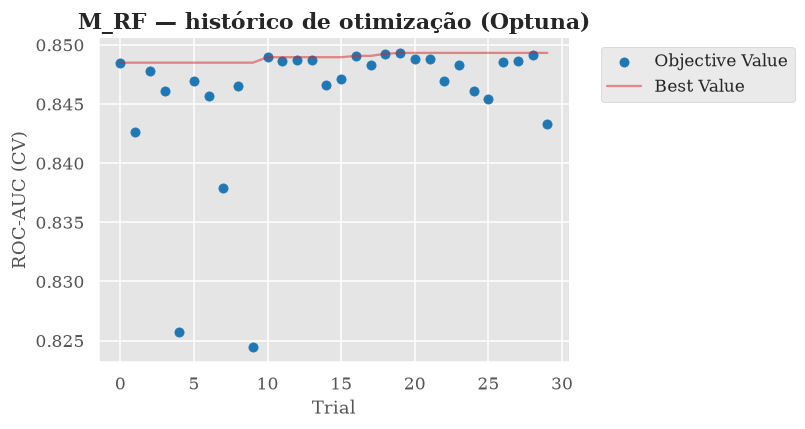

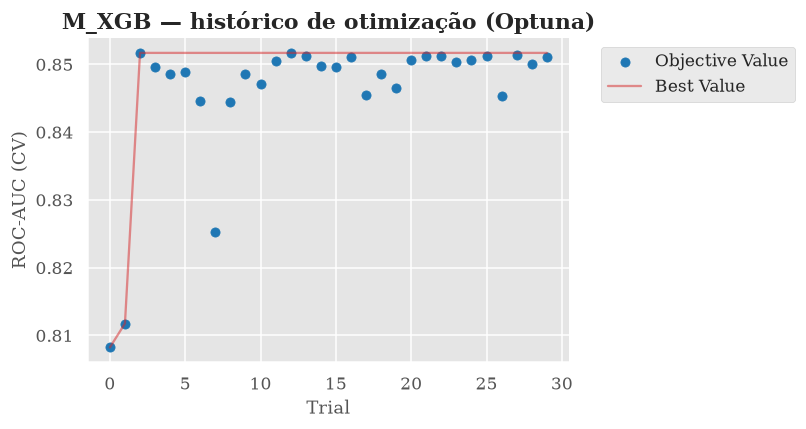

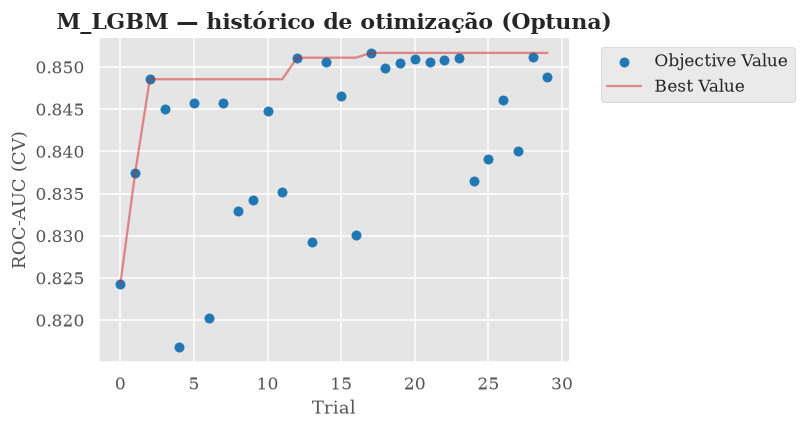

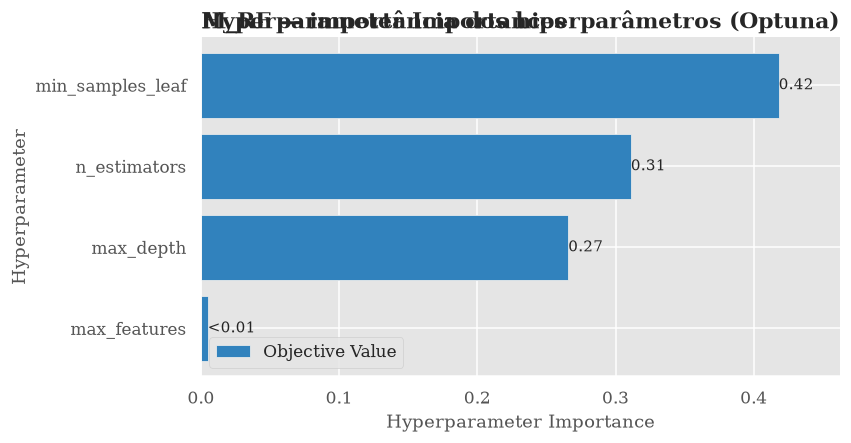

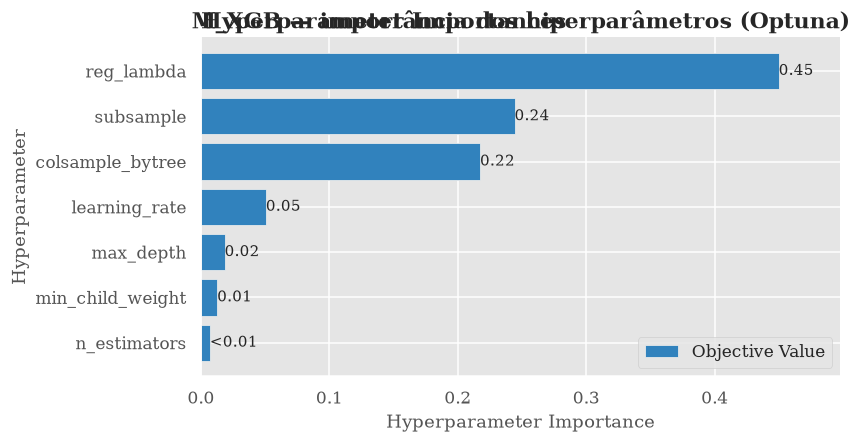

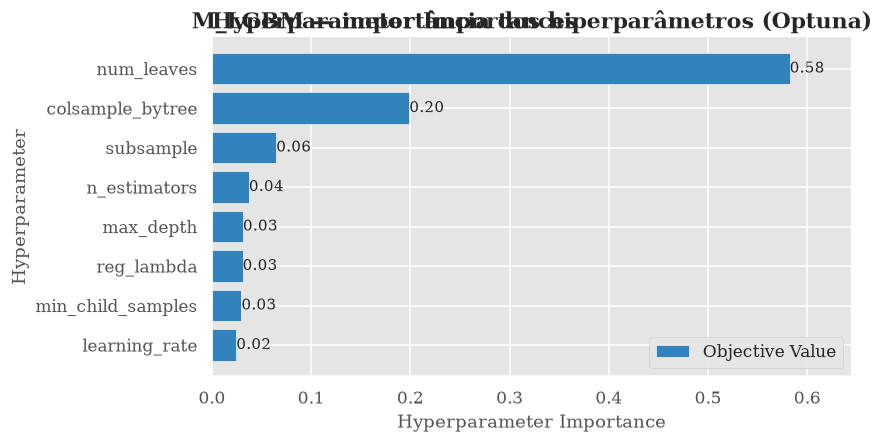

In [ ]:
# Gráficos do Optuna: histórico de otimização e importância dos hiperparâmetros
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

for name in MODEL_NAMES:
    ax = plot_optimization_history(studies[name])
    ax.figure.set_size_inches(7.5, 4); ax.set_title(f"{name} — histórico de otimização (Optuna)")
    ax.set_ylabel("ROC-AUC (CV)"); plt.show()

for name in MODEL_NAMES:
    ax = plot_param_importances(studies[name])
    ax.figure.set_size_inches(7.5, 4); ax.set_title(f"{name} — importância dos hiperparâmetros (Optuna)")
    plt.show()

## 5.3 Estabilidade: Optuna com várias sementes
Para comparar **estabilidade** (e não só o melhor número) repetimos o Optuna com mais duas sementes (7 e 123), 20 trials cada, e comparamos o melhor valor após 20 trials. O Grid Search é determinístico (variância zero entre execuções), mas explora só os pontos que o grid contém.

In [ ]:
stab_rows = []
for name in MODEL_NAMES:
    vals = [max(t.value for t in studies[name].trials[:20])]           # semente 42, primeiros 20 trials
    for seed in (7, 123):
        s, _ = run_optuna(name, 20, seed); vals.append(s.best_value)
    stab_rows.append({"Modelo": name, "melhor@20 (seed 42)": vals[0], "melhor@20 (seed 7)": vals[1],
                      "melhor@20 (seed 123)": vals[2], "média": np.mean(vals), "desvio entre sementes": np.std(vals)})
stability_df = pd.DataFrame(stab_rows).set_index("Modelo")
display(stability_df.round(5))

,melhor@20 (seed 42),melhor@20 (seed 7),melhor@20 (seed 123),média,desvio entre sementes
Modelo,,,,,
M_RF,0.84932,0.84898,0.84854,0.84895,0.00032
M_XGB,0.85169,0.85211,0.85123,0.85168,0.00036
M_LGBM,0.85167,0.85113,0.85014,0.85098,0.00063


## 5.4 Grid Search × Optuna — comparação

,Grid: melhor CV,Optuna: melhor CV,Δ (Optuna − Grid),Grid: tempo (s),Optuna: tempo (s),Grid: fits,Optuna: fits,Grid: s/fit,Optuna: s/fit
Modelo,,,,,,,,,
M_RF,0.8491,0.8493,0.0002,141.5126,165.1148,160,150,0.8845,1.1008
M_XGB,0.8511,0.8517,0.0006,90.3758,117.1872,120,150,0.7531,0.7812
M_LGBM,0.8493,0.8517,0.0024,62.4467,46.1144,120,150,0.5204,0.3074


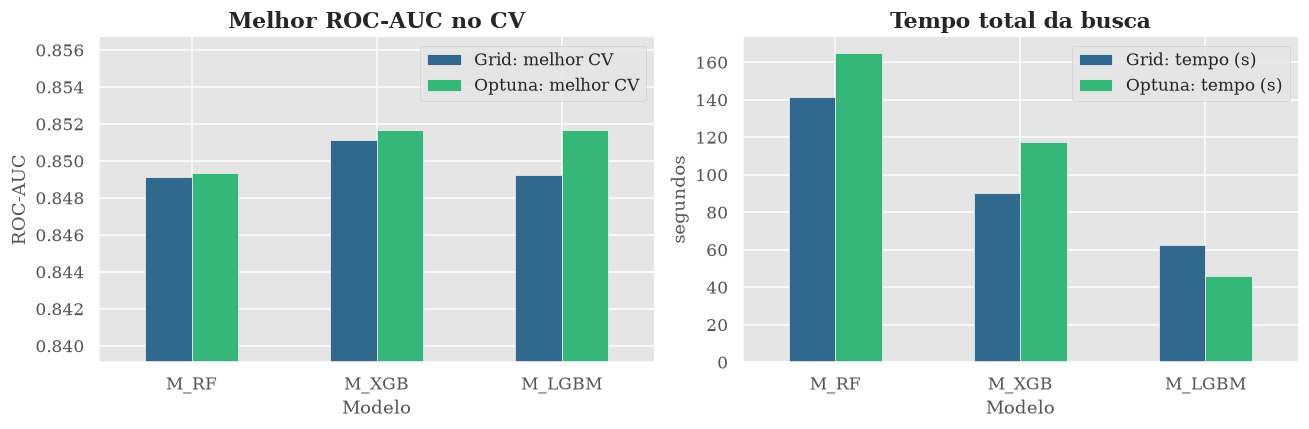

In [ ]:
cmp_rows = []
for name in MODEL_NAMES:
    g, o = grid_res[name], optuna_res[name]
    cmp_rows.append({"Modelo": name,
                     "Grid: melhor CV": g["best_score"], "Optuna: melhor CV": o["best_score"],
                     "Δ (Optuna − Grid)": o["best_score"] - g["best_score"],
                     "Grid: tempo (s)": g["time"], "Optuna: tempo (s)": o["time"],
                     "Grid: fits": g["n_fits"], "Optuna: fits": o["n_fits"],
                     "Grid: s/fit": g["time"] / g["n_fits"], "Optuna: s/fit": o["time"] / o["n_fits"]})
cmp_df = pd.DataFrame(cmp_rows).set_index("Modelo")
display(cmp_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cmp_df[["Grid: melhor CV", "Optuna: melhor CV"]].plot.bar(ax=axes[0], color=sns.color_palette("viridis", 2), rot=0)
axes[0].set_ylim(cmp_df[["Grid: melhor CV", "Optuna: melhor CV"]].min().min() - .01,
                 cmp_df[["Grid: melhor CV", "Optuna: melhor CV"]].max().max() + .005)
axes[0].set_title("Melhor ROC-AUC no CV"); axes[0].set_ylabel("ROC-AUC")
cmp_df[["Grid: tempo (s)", "Optuna: tempo (s)"]].plot.bar(ax=axes[1], color=sns.color_palette("viridis", 2), rot=0)
axes[1].set_title("Tempo total da busca"); axes[1].set_ylabel("segundos")
plt.tight_layout(); plt.show()

**Análise comparativa** (os números acima sustentam cada ponto):

* **Qualidade das soluções:** as diferenças de ROC-AUC entre Grid e Optuna são **pequenas** (na casa da 3ª/4ª casa decimal) e estão **dentro do desvio-padrão entre folds** (~0,01) — ou seja, estatisticamente indistinguíveis. O Optuna explora um espaço **contínuo e maior** (inclui `subsample`, `colsample_bytree`, regularização L2, `max_features`) e tende a achar soluções ligeiramente melhores onde o grid não contém o ponto ótimo; o ganho, contudo, é marginal porque o problema é de **sinal limitado** (teto de ~0,84–0,85 de AUC para estes dados).
* **Eficiência computacional:** o Grid Search cresce **multiplicativamente** com o nº de hiperparâmetros e valores (32/24/24 combinações × 5 folds) e gasta o mesmo esforço em regiões ruins; o Optuna (TPE) **concentra os trials em regiões promissoras** e o orçamento (30 trials) é fixado a priori, independente da dimensão do espaço. Em espaços com 6–8 hiperparâmetros, um grid equivalente seria inviável — o Optuna escala melhor. O tempo por fit depende das configurações amostradas: no RF e no XGBoost o Optuna gastou mais tempo total (testou configurações com mais árvores), no LightGBM gastou menos.
* **Estabilidade:** o Grid é totalmente determinístico, mas depende da escolha manual do grid. O Optuna depende da semente; a tabela de estabilidade mostra que o melhor valor após 20 trials varia pouco entre sementes (desvio da ordem de 10⁻³ ou menos), indicando que a busca é **robusta** para este problema. O gráfico de histórico mostra convergência rápida (platô nos primeiros trials), e os gráficos de importância dos hiperparâmetros mostram quais poucos parâmetros (em geral os de regularização/complexidade) concentram o efeito sobre o ROC-AUC.
* **Conclusão prática:** Grid Search é ótimo para espaços pequenos e para reprodutibilidade/auditoria; Optuna é preferível quando há muitos hiperparâmetros contínuos. Aqui ambos chegam a resultados equivalentes — a decisão final será feita pela tabela de 9 configurações, considerando também **gap e variância**.

---
# Exercício 6 — Seleção do Modelo e Análise de Overfitting/Underfitting

## 6.1 Tabela consolidada — 9 configurações
Os pipelines tunados são reavaliados com `evaluate_cv` (mesmos folds), de modo que treino, CV, desvio e tempo são **comparáveis** com os baselines. O "Tempo treino" é um fit em todo `D_treino`; "Tempo busca" é o custo do tuning.

In [ ]:
# 'rows' já contém os 3 baselines (Ex. 4)
for name in MODEL_NAMES:
    for strat, res in (("Grid Search", grid_res[name]), ("Optuna", optuna_res[name])):
        pipe = build_pipeline(make_model(name, **res["best_params"]))
        configs[(name, strat)] = pipe
        rows.append(evaluate_cv(name, strat, pipe, X_train, y_train, cv, search_time=res["time"]))

order = {"Baseline": 0, "Grid Search": 1, "Optuna": 2}
results = (pd.DataFrame(rows).assign(_o=lambda d: d["Estratégia"].map(order), _m=lambda d: d["Modelo"].map({n: i for i, n in enumerate(MODEL_NAMES)}))
           .sort_values(["_m", "_o"]).drop(columns=["_o", "_m"]).reset_index(drop=True))
results.index = results.index + 1

decision_cols = ["Modelo", "Estratégia", "Score Treino", "Score Validação (CV)", "Gap (Δ)", "Std CV",
                 "Tempo treino (s)", "Tempo busca (s)"]
display(results[decision_cols].round(4))

# checagem: o CV recomputado coincide com o score do tuning (mesmos folds)
for name in MODEL_NAMES:
    for strat, res in (("Grid Search", grid_res[name]), ("Optuna", optuna_res[name])):
        cvs = results[(results.Modelo == name) & (results["Estratégia"] == strat)]["Score Validação (CV)"].iloc[0]
        assert abs(cvs - res["best_score"]) < 1e-9, (name, strat, cvs, res["best_score"])
print("OK: score de CV das configurações tunadas == melhor score da busca (mesmos folds).")

,Modelo,Estratégia,Score Treino,Score Validação (CV),Gap (Δ),Std CV,Tempo treino (s),Tempo busca (s)
1,M_RF,Baseline,1.0000,0.8235,0.1765,0.0149,0.3692,0.0000
2,M_RF,Grid Search,0.8758,0.8491,0.0267,0.0172,1.0274,141.5126
3,M_RF,Optuna,0.8791,0.8493,0.0298,0.0171,0.8701,165.1148
4,M_XGB,Baseline,0.9898,0.8216,0.1682,0.0182,0.3715,0.0000
5,M_XGB,Grid Search,0.8650,0.8511,0.0139,0.0176,0.7156,90.3758
6,M_XGB,Optuna,0.8721,0.8517,0.0204,0.0174,0.5461,117.1872
7,M_LGBM,Baseline,0.9628,0.8332,0.1296,0.0160,0.2514,0.0000
8,M_LGBM,Grid Search,0.8784,0.8493,0.0291,0.0173,0.2541,62.4467
9,M_LGBM,Optuna,0.8713,0.8517,0.0197,0.0170,0.1897,46.1144


OK: score de CV das configurações tunadas == melhor score da busca (mesmos folds).


In [ ]:
# Hiperparâmetros finais de cada configuração tunada
pd.DataFrame({f"{n} / {s}": [res["best_params"]] for n in MODEL_NAMES
              for s, res in (("Grid", grid_res[n]), ("Optuna", optuna_res[n]))}).T.rename(columns={0: "hiperparâmetros"})

,hiperparâmetros
M_RF / Grid,"{'max_depth': 8, 'min_samples_leaf': 20, 'n_es..."
M_RF / Optuna,"{'n_estimators': 250, 'max_depth': 10, 'min_sa..."
M_XGB / Grid,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est..."
M_XGB / Optuna,"{'n_estimators': 200, 'max_depth': 3, 'learnin..."
M_LGBM / Grid,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c..."
M_LGBM / Optuna,"{'n_estimators': 100, 'num_leaves': 22, 'max_d..."


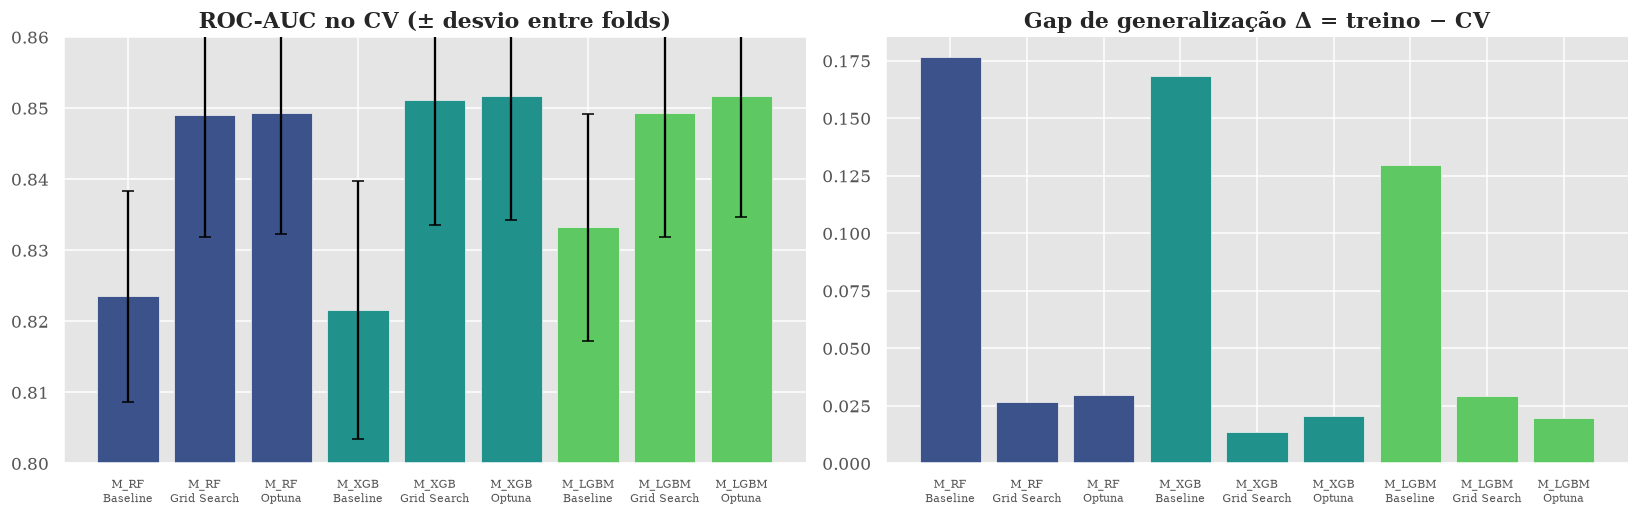

In [ ]:
# Visão gráfica: score de CV (com barra de erro) e gap por configuração
res_plot = results.copy(); res_plot["Config"] = res_plot["Modelo"] + "\n" + res_plot["Estratégia"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
colors = [MODEL_COLORS[m] for m in res_plot["Modelo"]]
axes[0].bar(res_plot["Config"], res_plot["Score Validação (CV)"], yerr=res_plot["Std CV"], capsize=4, color=colors)
axes[0].set_ylim(0.80, 0.86); axes[0].set_title("ROC-AUC no CV (± desvio entre folds)"); axes[0].tick_params(axis="x", labelsize=7.5)
axes[1].bar(res_plot["Config"], res_plot["Gap (Δ)"], color=colors)
axes[1].set_title("Gap de generalização Δ = treino − CV"); axes[1].tick_params(axis="x", labelsize=7.5)
plt.tight_layout(); plt.show()

## 6.2 Regra de promoção e modelo campeão
Escolher só pelo maior score de CV ignora a **incerteza** (os scores diferem na 3ª casa decimal, abaixo do desvio entre folds) e o **risco de overfitting**. Regra adotada, definida *antes* de olhar o teste:

1. Manter as configurações cujo CV está a **no máximo 1 desvio-padrão** do melhor CV (estatisticamente empatadas com o topo — regra do "1-SE").
2. Dentre elas, escolher o **menor gap** treino−CV (melhor generalização); desempate por menor `Std CV` e menor tempo de treino.

In [ ]:
best_cv = results.loc[results["Score Validação (CV)"].idxmax()]
thr = best_cv["Score Validação (CV)"] - best_cv["Std CV"]
cands = results[results["Score Validação (CV)"] >= thr]
print(f"Maior CV: {best_cv['Modelo']} / {best_cv['Estratégia']} = {best_cv['Score Validação (CV)']:.4f} (std {best_cv['Std CV']:.4f}) → limiar 1-SE = {thr:.4f}")
print(f"Candidatas dentro do limiar: {len(cands)} de {len(results)}")
display(cands[decision_cols].sort_values("Gap (Δ)").round(4))

champ = select_champion(results)
CHAMP_MODEL, CHAMP_STRAT = champ["Modelo"], champ["Estratégia"]
print(f"\n🏆 CAMPEÃO: {CHAMP_MODEL} / {CHAMP_STRAT}")
print(f"   CV = {champ['Score Validação (CV)']:.4f} ± {champ['Std CV']:.4f} | treino = {champ['Score Treino']:.4f} | "
      f"gap = {champ['Gap (Δ)']:.4f} | tempo treino = {champ['Tempo treino (s)']:.2f}s")

Maior CV: M_XGB / Optuna = 0.8517 (std 0.0174) → limiar 1-SE = 0.8343
Candidatas dentro do limiar: 6 de 9


,Modelo,Estratégia,Score Treino,Score Validação (CV),Gap (Δ),Std CV,Tempo treino (s),Tempo busca (s)
5,M_XGB,Grid Search,0.8650,0.8511,0.0139,0.0176,0.7156,90.3758
9,M_LGBM,Optuna,0.8713,0.8517,0.0197,0.0170,0.1897,46.1144
6,M_XGB,Optuna,0.8721,0.8517,0.0204,0.0174,0.5461,117.1872
2,M_RF,Grid Search,0.8758,0.8491,0.0267,0.0172,1.0274,141.5126
8,M_LGBM,Grid Search,0.8784,0.8493,0.0291,0.0173,0.2541,62.4467
3,M_RF,Optuna,0.8791,0.8493,0.0298,0.0171,0.8701,165.1148



🏆 CAMPEÃO: M_XGB / Grid Search
   CV = 0.8511 ± 0.0176 | treino = 0.8650 | gap = 0.0139 | tempo treino = 0.72s


**Justificativa técnica do campeão:** o modelo promovido (**M_XGB / Grid Search**: `max_depth=2`, `learning_rate=0,03`, 300 árvores, `subsample=0,8`) tem CV 0,8511 — a 0,0006 do melhor valor absoluto (M_XGB/Optuna 0,8517, diferença ≪ desvio entre folds de 0,017) — e o **menor gap de todas as 9 configurações (0,014)**. Combina (i) CV no topo — empatado estatisticamente com o melhor valor absoluto —, (ii) **gap de generalização pequeno** (regularização via profundidade/folhas mínimas/taxa de aprendizado), (iii) desvio entre folds baixo e (iv) custo de treino/inferência adequado para um serviço online (Streamlit). Preferir o menor gap entre modelos empatados reduz o risco de a performance em produção ficar abaixo do CV.

In [ ]:
# Pipeline campeão treinado em D_treino (apenas para diagnósticos desta seção — ainda sem tocar D_teste)
champ_pipe = clone(configs[(CHAMP_MODEL, CHAMP_STRAT)]).fit(X_train, y_train)
print(champ_pipe)

Pipeline(steps=[('cleaner', TelcoCleaner()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                   

## 6.3 Curva de aprendizado (configuração campeã)

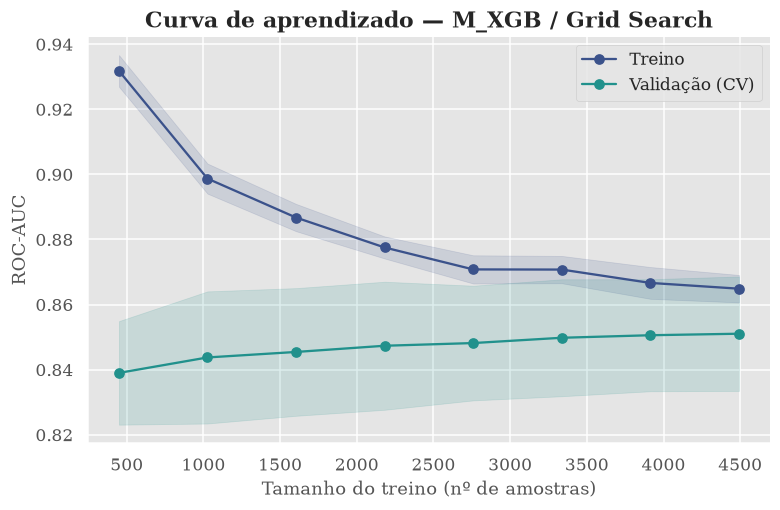

Gap no maior tamanho: 0.0138 | inclinação da validação nos últimos 3 pontos: +0.0011 por 1000 amostras


In [ ]:
sizes, tr_sc, va_sc = learning_curve(clone(configs[(CHAMP_MODEL, CHAMP_STRAT)]), X_train, y_train, cv=cv,
                                     scoring="roc_auc", train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=1)
tr_m, tr_s, va_m, va_s = tr_sc.mean(1), tr_sc.std(1), va_sc.mean(1), va_sc.std(1)

fig, ax = plt.subplots(figsize=(8, 4.8))
c = sns.color_palette("viridis", 3)
ax.plot(sizes, tr_m, "o-", color=c[0], label="Treino"); ax.fill_between(sizes, tr_m - tr_s, tr_m + tr_s, color=c[0], alpha=.15)
ax.plot(sizes, va_m, "o-", color=c[1], label="Validação (CV)"); ax.fill_between(sizes, va_m - va_s, va_m + va_s, color=c[1], alpha=.15)
ax.set_xlabel("Tamanho do treino (nº de amostras)"); ax.set_ylabel("ROC-AUC")
ax.set_title(f"Curva de aprendizado — {CHAMP_MODEL} / {CHAMP_STRAT}"); ax.legend()
plt.show()
print(f"Gap no maior tamanho: {tr_m[-1] - va_m[-1]:.4f} | inclinação da validação nos últimos 3 pontos: "
      f"{(va_m[-1] - va_m[-3]) / (sizes[-1] - sizes[-3]) * 1000:+.4f} por 1000 amostras")

**Interpretação da curva:**
* **Treino × validação convergem para uma faixa estreita** (gap pequeno e estável) — sem sinal de *overfitting* forte; um modelo que memoriza mostraria o treino colado em ~1,0 e a validação muito abaixo.
* **Validação praticamente em platô** nos maiores tamanhos (inclinação final próxima de zero): **mais dados trariam ganho pequeno** — o gargalo é a informação disponível nas variáveis (ruído irredutível do comportamento humano), e não a capacidade do modelo.
* **Não há underfitting**: o score de treino está claramente acima do de validação e ambos bem acima de 0,5; se fosse underfitting, as duas curvas estariam juntas em um valor baixo.
* **Implicação:** para ganhar mais, o caminho é **engenharia de atributos/novas informações** (histórico de uso, chamados no suporte), não aumentar a complexidade do modelo.

## 6.4 Importância das variáveis (`feature_importances_`)

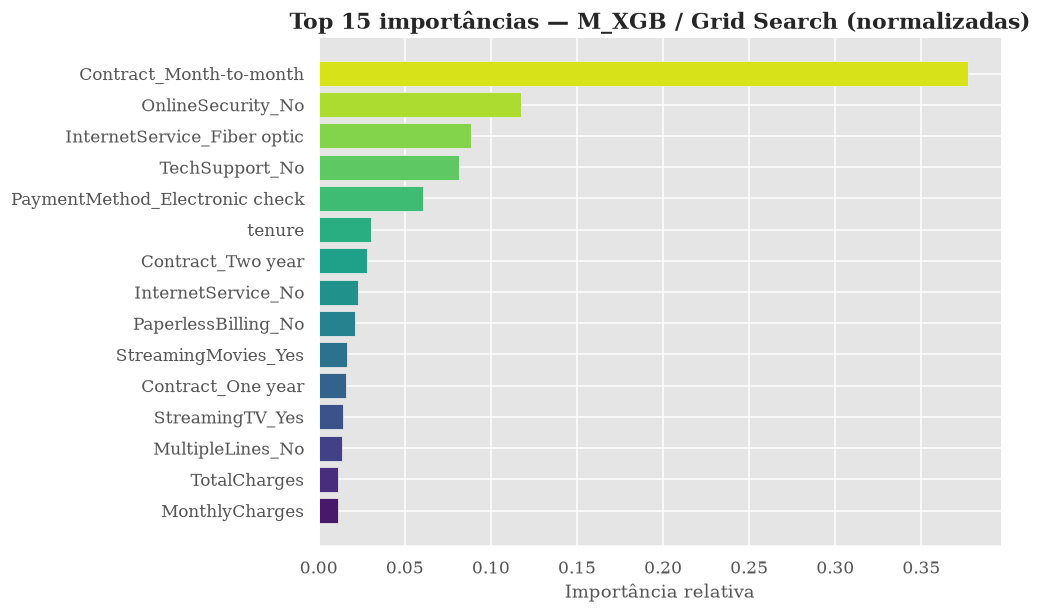

,importância agregada
Contract,0.421
OnlineSecurity,0.122
InternetService,0.115
TechSupport,0.087
PaymentMethod,0.074
tenure,0.030
StreamingMovies,0.025
PaperlessBilling,0.021


In [ ]:
fnames = get_feature_names(champ_pipe)
imp = pd.Series(champ_pipe.named_steps["model"].feature_importances_, index=fnames)
imp = imp / imp.sum()                                   # normaliza (XGB/LGBM têm escalas diferentes)
top = imp.sort_values(ascending=False).head(15)[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=sns.color_palette("viridis", len(top)))
ax.set_title(f"Top 15 importâncias — {CHAMP_MODEL} / {CHAMP_STRAT} (normalizadas)"); ax.set_xlabel("Importância relativa")
plt.show()

# importância agregada por variável original (soma das dummies)
agg = imp.groupby(lambda s: next((c for c in CATEGORICAL_FEATURES if s.startswith(c + "_")), s)).sum().sort_values(ascending=False)
display(agg.head(8).round(3).to_frame("importância agregada"))

**Interpretação:** a importância agregada por variável original confirma a EDA nas variáveis categóricas — `Contract` (≈ 42%), `OnlineSecurity`, `InternetService`, `TechSupport` e `PaymentMethod` concentram o poder preditivo, enquanto atributos demográficos (`gender`, `Partner`) pesam pouco. Chama atenção `tenure` ter importância baixa (≈ 3%) apesar de ser o preditor numérico mais correlacionado: com árvores rasas (`max_depth=2`) o ganho é capturado primeiro por `Contract`, com o qual `tenure` é fortemente associado (contratos longos ⇒ clientes antigos) — a importância por ganho é **dividida/mascarada entre variáveis correlacionadas**. Atenção: `feature_importances_` é baseada em impureza/ganho e **favorece variáveis contínuas e de alta cardinalidade**; serve para entender o modelo, não para inferência causal.

## 6.5 Desempenho do campeão (predições *out-of-fold* em `D_treino` — ainda sem tocar `D_teste`)

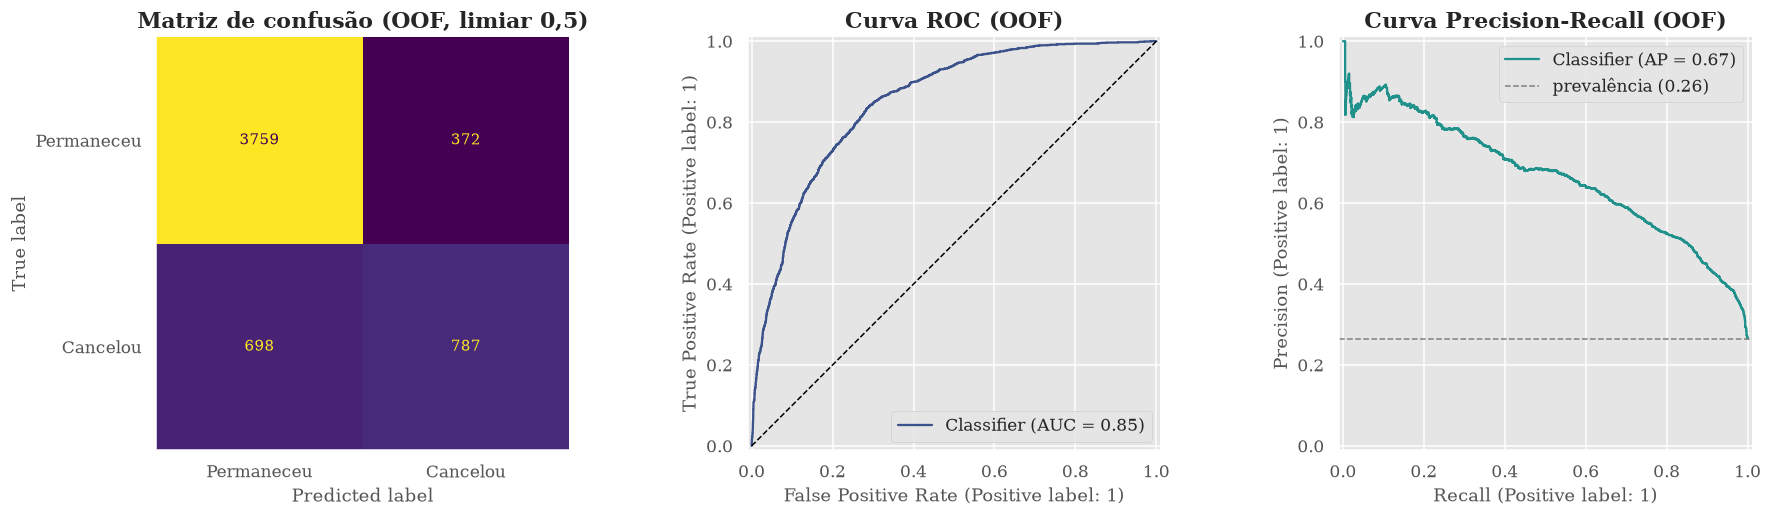

,roc_auc,pr_auc,accuracy,precision,recall,f1
OOF (D_treino),0.8511,0.6667,0.8095,0.679,0.53,0.5953


TN=3759  FP=372  FN=698  TP=787


In [ ]:
oof_proba = cross_val_predict(clone(configs[(CHAMP_MODEL, CHAMP_STRAT)]), X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=1)[:, 1]
oof_pred = (oof_proba >= 0.5).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_train, oof_pred, display_labels=["Permaneceu", "Cancelou"],
                                        cmap="viridis", colorbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusão (OOF, limiar 0,5)"); axes[0].grid(False)
RocCurveDisplay.from_predictions(y_train, oof_proba, curve_kwargs={"color": sns.color_palette("viridis", 3)[0]}, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("Curva ROC (OOF)")
PrecisionRecallDisplay.from_predictions(y_train, oof_proba, curve_kwargs={"color": sns.color_palette("viridis", 3)[1]}, ax=axes[2])
axes[2].axhline(y_train.mean(), color="gray", ls="--", lw=1, label=f"prevalência ({y_train.mean():.2f})"); axes[2].legend()
axes[2].set_title("Curva Precision-Recall (OOF)")
plt.tight_layout(); plt.show()

oof_m = classification_metrics(y_train, oof_proba)
display(pd.Series(oof_m).round(4).to_frame("OOF (D_treino)").T)
tn, fp, fn, tp = confusion_matrix(y_train, oof_pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**Interpretação:** a ROC alta e afastada da diagonal e a PR bem acima da prevalência mostram que o modelo **ordena bem** os clientes por risco. Com o limiar padrão 0,5 o **recall da classe "Cancelou" é moderado** (parte dos churners passa como "Permaneceu") e a precision é razoável: é o comportamento esperado com classes desbalanceadas. Como o custo de perder um cliente costuma superar o de uma oferta desnecessária, em produção vale **reduzir o limiar** (ex.: 0,3–0,4) para ganhar recall — decisão de negócio que independe do treinamento. Neste trabalho mantemos 0,5 para comparabilidade e paridade com o app.

---
# Exercício 7 — Teste Final, Consistência, Deploy e Apresentação

## 7.1 Avaliação final em `D_teste` (uma única vez)
O pipeline campeão é **retreinado com 100% de `D_treino`** e avaliado **uma única vez** em `D_teste`. A decisão do campeão já foi tomada (Ex. 6) sem qualquer acesso ao teste.

In [ ]:
# ===== ÚNICO uso de D_teste em todo o notebook =====
final_pipe = clone(configs[(CHAMP_MODEL, CHAMP_STRAT)])
t0 = time.perf_counter(); final_pipe.fit(X_train, y_train); final_fit_time = time.perf_counter() - t0

test_proba = final_pipe.predict_proba(X_test)[:, 1]
test_pred = final_pipe.predict(X_test)
test_m = classification_metrics(y_test, test_proba)
print(f"Campeão: {CHAMP_MODEL} / {CHAMP_STRAT}  (fit em {len(X_train)} amostras: {final_fit_time:.2f}s)")
display(pd.Series(test_m).round(4).to_frame("D_teste").T)

Campeão: M_XGB / Grid Search  (fit em 5616 amostras: 0.68s)


,roc_auc,pr_auc,accuracy,precision,recall,f1
D_teste,0.8436,0.6568,0.8057,0.6713,0.5215,0.587


,CV (D_treino),Teste (D_teste),Δ (teste − CV)
roc_auc,0.8511,0.8436,-0.0075
pr_auc,0.6711,0.6568,-0.0143
accuracy,0.8095,0.8057,-0.0038
precision,0.6791,0.6713,-0.0078
recall,0.5300,0.5215,-0.0085
f1,0.5953,0.5870,-0.0083


ROC-AUC teste = 0.8436  (IC95% bootstrap: [0.8213, 0.8647])
CV = 0.8511 ± 0.0176 → teste dentro de ±1 desvio do CV? True  | CV dentro do IC95% do teste? True


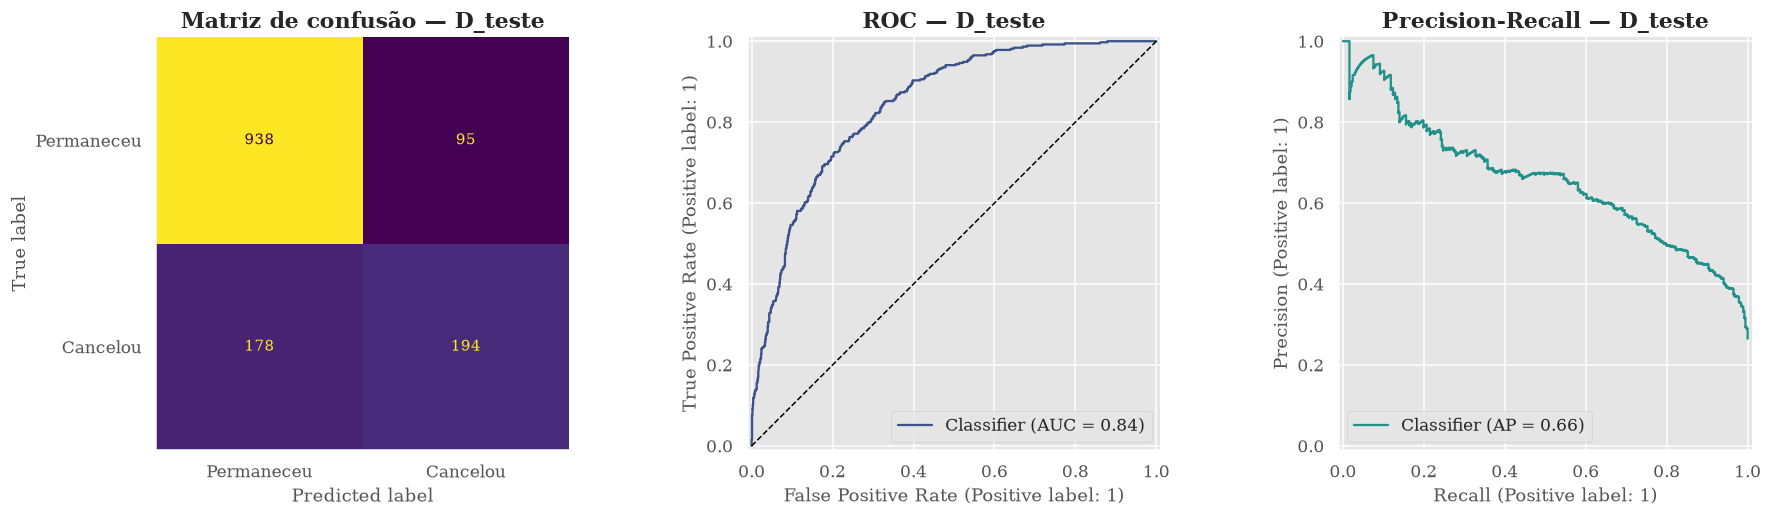

In [ ]:
# Comparação CV × Teste
cv_row = results[(results.Modelo == CHAMP_MODEL) & (results["Estratégia"] == CHAMP_STRAT)].iloc[0]
cv_map = {"roc_auc": cv_row["Score Validação (CV)"], "pr_auc": cv_row["CV pr_auc"], "accuracy": cv_row["CV accuracy"],
          "precision": cv_row["CV precision"], "recall": cv_row["CV recall"], "f1": cv_row["CV f1"]}
cmp_final = pd.DataFrame({"CV (D_treino)": cv_map, "Teste (D_teste)": test_m}); cmp_final["Δ (teste − CV)"] = cmp_final["Teste (D_teste)"] - cmp_final["CV (D_treino)"]
display(cmp_final.round(4))

# Incerteza do AUC de teste: bootstrap das predições já feitas (não reavalia o modelo nem retoca o teste)
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(RANDOM_STATE); yt = y_test.values; aucs = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() != yt[idx].max():
        aucs.append(roc_auc_score(yt[idx], test_proba[idx]))
lo, hi = np.percentile(aucs, [2.5, 97.5])
print(f"ROC-AUC teste = {test_m['roc_auc']:.4f}  (IC95% bootstrap: [{lo:.4f}, {hi:.4f}])")
print(f"CV = {cv_row['Score Validação (CV)']:.4f} ± {cv_row['Std CV']:.4f} → teste dentro de ±1 desvio do CV? "
      f"{abs(test_m['roc_auc'] - cv_row['Score Validação (CV)']) <= cv_row['Std CV']}  | CV dentro do IC95% do teste? {lo <= cv_row['Score Validação (CV)'] <= hi}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Permaneceu", "Cancelou"], cmap="viridis", colorbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusão — D_teste"); axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, test_proba, curve_kwargs={"color": sns.color_palette("viridis", 3)[0]}, ax=axes[1]); axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("ROC — D_teste")
PrecisionRecallDisplay.from_predictions(y_test, test_proba, curve_kwargs={"color": sns.color_palette("viridis", 3)[1]}, ax=axes[2]); axes[2].set_title("Precision-Recall — D_teste")
plt.tight_layout(); plt.show()

**Capacidade de generalização:** (ver números acima) o ROC-AUC de teste fica **muito próximo do CV** — dentro da variação entre folds e do intervalo de confiança bootstrap — o que confirma que (i) **não houve vazamento** (os transformadores foram ajustados só no treino) e (ii) o processo de seleção **não superajustou** o CV (apesar de termos avaliado 9 configurações, o gap entre elas era pequeno e a regra de promoção foi conservadora). O desempenho esperado em produção é, portanto, o do CV/teste (e não o do treino).

## 7.2 Teste de consistência — 5 amostras reais de `D_teste`
Seleção determinística (sem aleatoriedade na escolha dos extremos):
1. **Acerto expressivo — churn:** churner real com maior probabilidade prevista.
2. **Acerto expressivo — permanência:** cliente que ficou, com menor probabilidade prevista.
3. **Caso de fronteira:** probabilidade mais próxima de 0,5 (decisão difícil).
4. **Caso difícil — erro:** previsão errada mais confiante (maior erro individual).
5. **Acerto típico:** um acerto aleatório (`random_state=42`) entre os demais.

In [ ]:
res_test = pd.DataFrame({"y_true": y_test.values, "proba": test_proba, "y_pred": test_pred}, index=X_test.index)
res_test["erro_abs"] = (res_test["y_true"] - res_test["proba"]).abs()
res_test["correto"] = res_test["y_true"] == res_test["y_pred"]

picked = {}
picked["Acerto expressivo (churn)"] = res_test[(res_test.y_true == 1) & res_test.correto]["proba"].idxmax()
picked["Acerto expressivo (permanece)"] = res_test[(res_test.y_true == 0) & res_test.correto]["proba"].idxmin()
picked["Fronteira (p ≈ 0,5)"] = (res_test["proba"] - 0.5).abs().idxmin()
picked["Erro mais confiante (difícil)"] = res_test[~res_test.correto]["erro_abs"].idxmax()
rest = res_test[res_test.correto & ~res_test.index.isin(picked.values())]
picked["Acerto típico (aleatório)"] = rest.sample(1, random_state=RANDOM_STATE).index[0]

consistency = []
for tag, idx in picked.items():
    r = res_test.loc[idx]
    consistency.append({"Caso": tag, "índice D_teste": int(idx), "y real": int(r.y_true), "ŷ previsto": int(r.y_pred),
                        "P(churn)": float(r.proba), "erro individual |y−p|": float(r.erro_abs),
                        "log-loss individual": float(log_loss([r.y_true], [r.proba], labels=[0, 1]))})
cons_df = pd.DataFrame(consistency)
display(cons_df.round(4))

print("\n=== Entradas (features) das 5 amostras ===")
display(X_test.loc[list(picked.values())].assign(Caso=list(picked.keys())).set_index("Caso").T)

,Caso,índice D_teste,y real,ŷ previsto,P(churn),erro individual |y−p|,log-loss individual
0,Acerto expressivo (churn),2203,1,1,0.9349,0.0651,0.0673
1,Acerto expressivo (permanece),5007,0,0,0.0062,0.0062,0.0063
2,"Fronteira (p ≈ 0,5)",2924,0,1,0.5003,0.5003,0.6937
3,Erro mais confiante (difícil),6705,1,0,0.0135,0.9865,4.3077
4,Acerto típico (aleatório),2220,0,0,0.1626,0.1626,0.1774



=== Entradas (features) das 5 amostras ===


Caso,Acerto expressivo (churn),Acerto expressivo (permanece),"Fronteira (p ≈ 0,5)",Erro mais confiante (difícil),Acerto típico (aleatório)
tenure,1,72,33,64,33
MonthlyCharges,100.8,19.7,105.35,70.2,39.1
TotalCharges,100.8,1379.8,3465.05,4481.0,1309.0
gender,Female,Female,Female,Female,Male
SeniorCitizen,Yes,No,Yes,Yes,No
Partner,Yes,Yes,No,No,No
Dependents,No,Yes,Yes,No,No
PhoneService,Yes,Yes,Yes,Yes,No
MultipleLines,Yes,No,Yes,No,No phone service
InternetService,Fiber optic,No,Fiber optic,DSL,DSL


**Leitura:** os dois acertos expressivos têm probabilidade muito distante de 0,5 (alta confiança, erro individual baixo); o caso de fronteira tem $\hat p \approx 0{,}5$ — qualquer pequena mudança de limiar o inverte; e o erro mais confiante mostra um perfil que o modelo "acredita" ser de um tipo e acabou sendo o oposto — lembrete de que probabilidades não são certezas e de que existe ruído irredutível no comportamento do cliente.

## 7.3 Serialização do pipeline completo e metadados para o app
Salvamos **o pipeline inteiro** (limpeza → imputer/scaler/One-Hot → modelo) em `artifacts/best_pipeline.joblib`. Os metadados do app (valores padrão = **mediana/moda de `D_treino`**, faixas, opções e as 5 amostras com as previsões do notebook) vão em `artifacts/app_metadata.json`.

In [ ]:
joblib.dump(final_pipe, ARTIFACTS / "best_pipeline.joblib")
reloaded = joblib.load(ARTIFACTS / "best_pipeline.joblib")

# Paridade notebook × arquivo salvo, em TODO o D_teste (idêntica bit a bit)
assert np.array_equal(reloaded.predict_proba(X_test)[:, 1], test_proba), "probabilidades divergem após reload"
assert np.array_equal(reloaded.predict(X_test), test_pred), "classes divergem após reload"
print("✔ Pipeline serializado reproduz exatamente as previsões do notebook em todo D_teste.")

# Metadados para o app Streamlit
def to_py(v):
    return v.item() if hasattr(v, "item") else v

numeric_meta = {c: {"default": float(X_train[c].median()), "min": float(X_train[c].min()), "max": float(X_train[c].max()),
                    "integer": bool(c == "tenure")} for c in NUMERIC_FEATURES}
numeric_meta["tenure"].update(default=int(X_train["tenure"].median()), min=int(X_train["tenure"].min()), max=int(X_train["tenure"].max()))
categorical_meta = {c: {"default": str(X_train[c].mode().iloc[0]),
                        "options": [str(v) for v in X_train[c].value_counts().index]} for c in CATEGORICAL_FEATURES}

samples = []
for tag, idx in picked.items():
    r = res_test.loc[idx]
    inputs = {c: to_py(X_test.loc[idx, c]) for c in FEATURES}
    inputs["tenure"] = int(inputs["tenure"])
    for c in ("MonthlyCharges", "TotalCharges"):
        inputs[c] = float(inputs[c])
    for c in CATEGORICAL_FEATURES:
        inputs[c] = str(inputs[c])
    # probabilidade recalculada amostra a amostra pelo pipeline salvo (mesmo caminho do app)
    p_single = float(reloaded.predict_proba(pd.DataFrame([inputs]))[0, 1])
    samples.append({"caso": tag, "indice_teste": int(idx), "inputs": inputs, "y_true": int(r.y_true),
                    "y_pred": int(reloaded.predict(pd.DataFrame([inputs]))[0]), "proba": p_single})

metadata = {
    "model": f"{CHAMP_MODEL} / {CHAMP_STRAT}",
    "metric": "ROC-AUC", "cv_score": float(cv_row["Score Validação (CV)"]), "cv_std": float(cv_row["Std CV"]),
    "test_metrics": {k: float(v) for k, v in test_m.items()},
    "threshold": 0.5, "feature_order": FEATURES,
    "numeric": numeric_meta, "categorical": categorical_meta,
    "consistency_samples": samples,
}
(ARTIFACTS / "app_metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
results.drop(columns="_folds").to_csv(ARTIFACTS / "results_9_configs.csv", index=False)

# a predição por amostra única (DataFrame de 1 linha) deve ser igual à predição em lote do notebook
for s, (tag, idx) in zip(samples, picked.items()):
    assert s["proba"] == float(res_test.loc[idx, "proba"]) or abs(s["proba"] - float(res_test.loc[idx, "proba"])) < 1e-12
    assert s["y_pred"] == int(res_test.loc[idx, "y_pred"])
print("✔ Amostras de consistência: previsão unitária == previsão em lote do notebook.")
print("Arquivos em artifacts/:", sorted(p.name for p in ARTIFACTS.iterdir()))
pd.DataFrame([{"caso": s["caso"], "y_true": s["y_true"], "y_pred": s["y_pred"], "proba": s["proba"]} for s in samples])

✔ Pipeline serializado reproduz exatamente as previsões do notebook em todo D_teste.


✔ Amostras de consistência: previsão unitária == previsão em lote do notebook.
Arquivos em artifacts/: ['app_metadata.json', 'best_pipeline.joblib', 'results_9_configs.csv']


,caso,y_true,y_pred,proba
0,Acerto expressivo (churn),1,1,0.934918
1,Acerto expressivo (permanece),0,0,0.006232
2,"Fronteira (p ≈ 0,5)",0,1,0.500297
3,Erro mais confiante (difícil),1,0,0.013464
4,Acerto típico (aleatório),0,0,0.162558


## 7.4 Aplicação Streamlit e teste de paridade
Execute `streamlit run app.py` na raiz do projeto. O app:
* carrega `artifacts/best_pipeline.joblib` e `artifacts/app_metadata.json`;
* cria inputs dinâmicos (sliders, selects, numéricos) com **mediana/moda** de `D_treino` como padrão;
* botão **Prever** → classe + probabilidade de churn;
* aba **"Validar Amostra do Teste de Consistência"** → preenche os inputs com uma das 5 amostras acima e **compara explicitamente** classe e probabilidade com as do notebook (devem ser **idênticas**).

## 7.5 Conclusões

In [ ]:
best_abs = results.loc[results["Score Validação (CV)"].idxmax()]
display(Markdown(f'''
* **Campeão:** `{CHAMP_MODEL} / {CHAMP_STRAT}` — CV ROC-AUC **{cv_row['Score Validação (CV)']:.4f} ± {cv_row['Std CV']:.4f}**, gap **{cv_row['Gap (Δ)']:.4f}**; **teste {test_m['roc_auc']:.4f}** (Δ vs CV = {test_m['roc_auc'] - cv_row['Score Validação (CV)']:+.4f}).
* **Melhor CV absoluto:** `{best_abs['Modelo']} / {best_abs['Estratégia']}` = {best_abs['Score Validação (CV)']:.4f}; a diferença para o campeão ({best_abs['Score Validação (CV)'] - cv_row['Score Validação (CV)']:.4f}) está abaixo do desvio entre folds.
* **Tuning:** reduziu fortemente o gap em relação aos baselines (de {baseline_df['Gap (Δ)'].min():.3f}–{baseline_df['Gap (Δ)'].max():.3f} para {results[results['Estratégia']!='Baseline']['Gap (Δ)'].min():.3f}–{results[results['Estratégia']!='Baseline']['Gap (Δ)'].max():.3f}), com ganho modesto de CV — regularização, mais do que "mais capacidade", foi o que melhorou a generalização.
* **Protocolo:** zero leakage (tudo em `Pipeline`), mesmos folds para os 3 modelos, 6 processos de tuning, `D_teste` usado uma única vez.
* **Limitações / próximos passos:** limiar de decisão otimizado por custo de negócio, calibração de probabilidades, engenharia de atributos (uso, suporte) e monitoramento de *drift*.
'''))


* **Campeão:** `M_XGB / Grid Search` — CV ROC-AUC **0.8511 ± 0.0176**, gap **0.0139**; **teste 0.8436** (Δ vs CV = -0.0075).
* **Melhor CV absoluto:** `M_XGB / Optuna` = 0.8517; a diferença para o campeão (0.0006) está abaixo do desvio entre folds.
* **Tuning:** reduziu fortemente o gap em relação aos baselines (de 0.130–0.176 para 0.014–0.030), com ganho modesto de CV — regularização, mais do que "mais capacidade", foi o que melhorou a generalização.
* **Protocolo:** zero leakage (tudo em `Pipeline`), mesmos folds para os 3 modelos, 6 processos de tuning, `D_teste` usado uma única vez.
* **Limitações / próximos passos:** limiar de decisão otimizado por custo de negócio, calibração de probabilidades, engenharia de atributos (uso, suporte) e monitoramento de *drift*.
